# ACL Project, Team 10: predicting Formula 1 podiums

**Task.** For every driver in a race, predict whether they finish on the podium (`positionOrder ≤ 3`) using only
information available **after qualifying and before the race starts**.

**Data.** Formula 1 World Championship 1950–2024 (Kaggle / Ergast): 14 CSV tables.

**Notebook map**
0. Setup · 1. Audit · 2. Raw EDA · 3. Cleaning · 4. After-cleaning EDA · 5. Modeling table v1

Every cleaning and modeling choice is logged with its evidence in the repository's `decisions.md`.

## 0. Setup
Imports, a fixed random seed, and loading the 14 tables. Two copies of every table are kept:
`raw` (exactly as read from disk, never modified) and `df` (working copies; all cleaning happens there).

### 0.1 Imports and random seed
One global seed so that **Run All** gives the same numbers every time.

In [1]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
# (TensorFlow seed is set later, in the modeling section: tf.random.set_seed(SEED))
 
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

### 0.2 Locate the dataset

In [2]:
matches = glob.glob("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv", recursive=True)
assert len(matches) == 1, f"expected one results.csv, found: {matches}"
DATA_DIR = os.path.dirname(matches[0])
print("DATA_DIR =", DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

DATA_DIR = /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
['circuits.csv', 'constructor_results.csv', 'constructor_standings.csv', 'constructors.csv', 'driver_standings.csv', 'drivers.csv', 'lap_times.csv', 'pit_stops.csv', 'qualifying.csv', 'races.csv', 'results.csv', 'seasons.csv', 'sprint_results.csv', 'status.csv']


### 0.3 Load the 14 tables
Missing values in these files are written as the literal text `\N`. We read **only** `\N` and empty cells as
missing (`keep_default_na=False`), so legitimate strings such as `"NA"` are not silently turned into missing values.

In [3]:
TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "races", "results", "qualifying",
    "lap_times", "pit_stops", "sprint_results", "seasons", "status",
]
 
def load_table(name):
    """Read one CSV. Only the literal \\N (and empty cells) become NaN, so legitimate
    strings like 'NA' are not silently turned into missing values."""
    return pd.read_csv(
        os.path.join(DATA_DIR, f"{name}.csv"),
        na_values=[r"\N", ""],
        keep_default_na=False,
    )
 
raw = {name: load_table(name) for name in TABLES}   # bronze: NEVER modify these
df = {name: t.copy() for name, t in raw.items()}    # working copies: all cleaning happens here

### 0.4 Rows, columns and missing cells per table

In [4]:
summary = pd.DataFrame({
    "rows": {n: len(t) for n, t in raw.items()},
    "cols": {n: t.shape[1] for n, t in raw.items()},
    "missing_cells": {n: int(t.isna().sum().sum()) for n, t in raw.items()},
}).sort_values("rows", ascending=False)
summary

,rows,cols,missing_cells
lap_times,589081,6,0
driver_standings,34863,7,0
results,26759,18,122887
constructor_standings,13391,7,0
constructor_results,12625,5,12608
pit_stops,11371,7,0
qualifying,10494,9,11668
races,1125,18,11349
drivers,861,9,1559
sprint_results,360,16,73


## 1. Audit: what is in the 14 tables?

Before cleaning anything we answer six questions for every table: what is one row, is the key unique,
are the types right, what do categories look like, where are the nulls, what are the ranges.
Nothing in this section modifies data; `raw` stays untouched and all findings feed the cleaning in §3.

**How the tables fit together** (one race weekend = one `raceId`):

| Group | Tables | One row is | Can the *current race's* value be a feature? |
|---|---|---|---|
| Lookups: who / where / when | `drivers`, `constructors`, `circuits`, `races`, `seasons`, `status` | one driver / team / track / race / year / status label | yes (except `status`, which describes how a race ended) |
| Before the race | `qualifying` | one driver's qualifying result in one race | **yes** |
| The race itself | `results`, `sprint_results`, `lap_times`, `pit_stops` | one driver in one race / sprint / lap / pit stop | **no**, except `results.grid` (the starting slot). Past races are fine |
| After the race | `driver_standings`, `constructor_standings`, `constructor_results` | the championship table / team points **after** a race | **no** for the current race; the previous race's table is fine |

Our modeling grain is **one row per (raceId, driverId)**, built from `results`.

### 1.1 Profiling function
One row per column, answering the six questions at once: type (`dtype`, Python types), missing values, distinct
values, range (min/max), and most common values. `numeric-looking %` flags text columns whose values are really numbers.

In [5]:
from IPython.display import display, Markdown

def profile(frame):
    """One row per column: the six audit questions answered for every column at once."""
    rows = {}
    for name, column in frame.items():
        numeric = pd.api.types.is_numeric_dtype(column)
        values = column.dropna()
        rows[name] = {
            "dtype": str(column.dtype),
            "python types": ", ".join(sorted(values.map(lambda v: type(v).__name__).unique())),
            "missing": int(column.isna().sum()),
            "missing %": round(100 * column.isna().mean(), 1),
            "distinct": int(column.nunique()),
            "min": column.min() if numeric else None,
            "max": column.max() if numeric else None,
            # for text columns: how many of the values would parse as a plain number?
            "numeric-looking %": None if numeric or values.empty
                else round(100 * pd.to_numeric(values, errors="coerce").notna().mean(), 1),
            "most common": column.value_counts().head(3).to_dict(),
        }
    return pd.DataFrame.from_dict(rows, orient="index")

### 1.2 Profile of every table

In [6]:
profiles = {}
for name in TABLES:
    profiles[name] = profile(raw[name])
    display(Markdown(f"### `{name}`: {len(raw[name]):,} rows × {raw[name].shape[1]} columns"))
    display(profiles[name])

### `circuits`: 77 rows × 9 columns

,dtype,python types,missing,missing %,distinct,min,max,numeric-looking %,most common
circuitId,int64,int,0,0.0,77,1.0000,80.0000,NaN,"{1: 1, 2: 1, 3: 1}"
circuitRef,object,str,0,0.0,77,NaN,NaN,0.0,"{'albert_park': 1, 'sepang': 1, 'bahrain': 1}"
name,object,str,0,0.0,77,NaN,NaN,0.0,"{'Albert Park Grand Prix Circuit': 1, 'Sepang ..."
location,object,str,0,0.0,75,NaN,NaN,0.0,"{'California': 2, 'Barcelona': 2, 'Melbourne': 1}"
country,object,str,0,0.0,35,NaN,NaN,0.0,"{'USA': 11, 'France': 7, 'Spain': 6}"
lat,float64,float,0,0.0,77,-37.8497,57.2653,NaN,"{-37.8497: 1, 2.76083: 1, 26.0325: 1}"
lng,float64,float,0,0.0,77,-118.1890,144.9680,NaN,"{144.968: 1, 101.738: 1, 50.5106: 1}"
alt,int64,int,0,0.0,66,-7.0000,2227.0000,NaN,"{18: 3, 7: 2, 15: 2}"
url,object,str,0,0.0,77,NaN,NaN,0.0,{'http://en.wikipedia.org/wiki/Melbourne_Grand...


### `constructors`: 212 rows × 5 columns

,dtype,python types,missing,missing %,distinct,min,max,numeric-looking %,most common
constructorId,int64,int,0,0.0,212,1.0,215.0,NaN,"{1: 1, 2: 1, 3: 1}"
constructorRef,object,str,0,0.0,212,NaN,NaN,0.0,"{'mclaren': 1, 'bmw_sauber': 1, 'williams': 1}"
name,object,str,0,0.0,212,NaN,NaN,0.0,"{'McLaren': 1, 'BMW Sauber': 1, 'Williams': 1}"
nationality,object,str,0,0.0,24,NaN,NaN,0.0,"{'British': 86, 'American': 39, 'Italian': 30}"
url,object,str,0,0.0,175,NaN,NaN,0.0,{'http://en.wikipedia.org/wiki/Cooper_Car_Comp...


### `constructor_results`: 12,625 rows × 5 columns

...

,dtype,python types,missing,missing %,distinct,min,max,numeric-looking %,most common
resultId,int64,int,0,0.0,360,1.0,360.0,NaN,"{360: 1, 1: 1, 2: 1}"
raceId,int64,int,0,0.0,18,1061.0,1143.0,NaN,"{1061: 20, 1065: 20, 1071: 20}"
driverId,int64,int,0,0.0,31,1.0,861.0,NaN,"{830: 18, 1: 18, 822: 18}"
constructorId,int64,int,0,0.0,12,1.0,215.0,NaN,"{9: 36, 131: 36, 6: 36}"
number,int64,int,0,0.0,33,1.0,99.0,NaN,"{44: 18, 22: 18, 77: 18}"
grid,int64,int,0,0.0,21,0.0,20.0,NaN,"{2: 18, 1: 18, 3: 18}"
position,float64,float,15,4.2,20,1.0,20.0,NaN,"{1.0: 18, 2.0: 18, 3.0: 18}"
positionText,object,str,0,0.0,23,NaN,NaN,95.8,"{'1': 18, '2': 18, '3': 18}"
positionOrder,int64,int,0,0.0,20,1.0,20.0,NaN,"{1: 18, 2: 18, 3: 18}"
points,int64,int,0,0.0,9,0.0,8.0,NaN,"{0: 231, 3: 18, 2: 18}"


### `seasons`: 75 rows × 2 columns

,dtype,python types,missing,missing %,distinct,min,max,numeric-looking %,most common
year,int64,int,0,0.0,75,1950.0,2024.0,NaN,"{2009: 1, 2008: 1, 2007: 1}"
url,object,str,0,0.0,75,NaN,NaN,0.0,{'http://en.wikipedia.org/wiki/2009_Formula_On...


### `status`: 139 rows × 2 columns

,dtype,python types,missing,missing %,distinct,min,max,numeric-looking %,most common
statusId,int64,int,0,0.0,139,1.0,141.0,NaN,"{1: 1, 2: 1, 3: 1}"
status,object,str,0,0.0,139,NaN,NaN,0.0,"{'Finished': 1, 'Disqualified': 1, 'Accident': 1}"


### 1.3 Text columns and what they hide
Every non-numeric column of every table, with examples. Dates and lap times stored as text are converted in §3.1.

In [7]:
text_cols = []
for name in TABLES:
    p = profiles[name]
    for col, r in p[p["numeric-looking %"].notna()].iterrows():
        text_cols.append({
            "table": name,
            "column": col,
            "missing %": r["missing %"],
            "numeric-looking %": r["numeric-looking %"],
            "examples": raw[name][col].dropna().drop_duplicates().head(4).tolist(),
        })
text_cols = pd.DataFrame(text_cols)
text_cols

,table,column,missing %,numeric-looking %,examples
0,circuits,circuitRef,0.0,0.0,"[albert_park, sepang, bahrain, catalunya]"
1,circuits,name,0.0,0.0,"[Albert Park Grand Prix Circuit, Sepang Intern..."
2,circuits,location,0.0,0.0,"[Melbourne, Kuala Lumpur, Sakhir, Montmeló]"
3,circuits,country,0.0,0.0,"[Australia, Malaysia, Bahrain, Spain]"
4,circuits,url,0.0,0.0,[http://en.wikipedia.org/wiki/Melbourne_Grand_...
5,constructors,constructorRef,0.0,0.0,"[mclaren, bmw_sauber, williams, renault]"
6,constructors,name,0.0,0.0,"[McLaren, BMW Sauber, Williams, Renault]"
7,constructors,nationality,0.0,0.0,"[British, German, French, Italian]"
8,constructors,url,0.0,0.0,"[http://en.wikipedia.org/wiki/McLaren, http://..."
9,constructor_results,status,99.9,0.0,[D]


### 1.4 Season coverage of each table
Not every table starts in 1950. A feature taken from a table that starts in 1994 is missing for every earlier race *by design*.

In [8]:
race_year = raw["races"].set_index("raceId")["year"]
coverage = []
for name in TABLES:
    t = raw[name]
    if name == "races" or "raceId" not in t.columns:
        continue
    years = t["raceId"].map(race_year)
    coverage.append({
        "table": name,
        "rows": len(t),
        "first season": years.min(),
        "last season": years.max(),
        "races covered": t["raceId"].nunique(),
        "rows whose race is unknown": int(years.isna().sum()),
    })
coverage = pd.DataFrame(coverage).set_index("table").sort_values("first season")
print(f"races.csv lists {raw['races']['raceId'].nunique():,} races, "
      f"seasons {raw['races']['year'].min()}–{raw['races']['year'].max()}")
coverage

races.csv lists 1,125 races, seasons 1950–2024


,rows,first season,last season,races covered,rows whose race is unknown
table,,,,,
results,26759,1950,2024,1125,0
driver_standings,34863,1950,2024,1125,0
constructor_standings,13391,1958,2024,1061,0
constructor_results,12625,1958,2024,1060,0
qualifying,10494,1994,2024,494,0
lap_times,589081,1996,2024,544,0
pit_stops,11371,2011,2024,285,0
sprint_results,360,2021,2024,18,0


### 1.5 Primary keys and grain keys
- **Primary key**: the id column a table is built around. Duplicated or missing → the file is broken, so we **assert**.
- **Grain key**: the "one row per …" we rely on when joining tables. Duplicates here are **reported**, not asserted,
  because a join on a non-unique key silently multiplies rows; they are fixed in §3.3.

In [9]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "sprint_results": ["resultId"], "qualifying": ["qualifyId"],
    "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
    "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
# "one row per ..." claims we will rely on when joining tables
GRAIN_KEYS = {
    "results": ["raceId", "driverId"], "qualifying": ["raceId", "driverId"],
    "sprint_results": ["raceId", "driverId"], "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"], "constructor_results": ["raceId", "constructorId"],
    "races": ["year", "round"], "drivers": ["driverRef"], "constructors": ["constructorRef"],
    "circuits": ["circuitRef"], "status": ["status"],
}

def key_check(name, cols):
    t = raw[name]
    extra = int(t.duplicated(subset=cols).sum())
    nulls = int(t[cols].isna().any(axis=1).sum())
    return {
        "table": name, "key": " + ".join(cols), "rows": len(t),
        "distinct keys": len(t) - extra,
        "rows sharing a key": int(t.duplicated(subset=cols, keep=False).sum()),
        "null keys": nulls,
        "OK": extra == 0 and nulls == 0,
    }

pk_report = pd.DataFrame([key_check(n, c) for n, c in PRIMARY_KEYS.items()]).set_index("table")
grain_report = pd.DataFrame([key_check(n, c) for n, c in GRAIN_KEYS.items()]).set_index("table")
display(Markdown("**Primary keys**")); display(pk_report)
display(Markdown("**Grain keys** (duplicates here are findings, not crashes)")); display(grain_report)
assert pk_report["OK"].all(), "a primary key is duplicated or null: see pk_report"

**Primary keys**

,key,rows,distinct keys,rows sharing a key,null keys,OK
table,,,,,,
circuits,circuitId,77,77,0,0,True
constructors,constructorId,212,212,0,0,True
drivers,driverId,861,861,0,0,True
races,raceId,1125,1125,0,0,True
seasons,year,75,75,0,0,True
status,statusId,139,139,0,0,True
results,resultId,26759,26759,0,0,True
sprint_results,resultId,360,360,0,0,True
qualifying,qualifyId,10494,10494,0,0,True


**Grain keys** (duplicates here are findings, not crashes)

,key,rows,distinct keys,rows sharing a key,null keys,OK
table,,,,,,
results,raceId + driverId,26759,26668,176,0,False
qualifying,raceId + driverId,10494,10494,0,0,True
sprint_results,raceId + driverId,360,360,0,0,True
driver_standings,raceId + driverId,34863,34863,0,0,True
constructor_standings,raceId + constructorId,13391,13391,0,0,True
constructor_results,raceId + constructorId,12625,12625,0,0,True
races,year + round,1125,1125,0,0,True
drivers,driverRef,861,861,0,0,True
constructors,constructorRef,212,212,0,0,True


### 1.6 Foreign keys
An *orphan* is an id that points at no row in its parent table (e.g. a result for a driver missing from `drivers`).
Orphans would be dropped by an inner join or get empty columns in a left join, so we count them before any join.

In [10]:
FOREIGN_KEYS = [  # (child table, column, parent table, parent column)
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
]
for child in ["results", "sprint_results", "qualifying"]:
    FOREIGN_KEYS += [(child, "raceId", "races", "raceId"),
                     (child, "driverId", "drivers", "driverId"),
                     (child, "constructorId", "constructors", "constructorId")]
for child in ["results", "sprint_results"]:
    FOREIGN_KEYS += [(child, "statusId", "status", "statusId")]
for child in ["driver_standings", "lap_times", "pit_stops"]:
    FOREIGN_KEYS += [(child, "raceId", "races", "raceId"), (child, "driverId", "drivers", "driverId")]
for child in ["constructor_standings", "constructor_results"]:
    FOREIGN_KEYS += [(child, "raceId", "races", "raceId"),
                     (child, "constructorId", "constructors", "constructorId")]

def fk_check(child, col, parent, pcol):
    values = raw[child][col]
    orphan = values.notna() & ~values.isin(set(raw[parent][pcol].dropna()))
    return {
        "foreign key": f"{child}.{col}", "points to": f"{parent}.{pcol}",
        "rows": len(values), "null": int(values.isna().sum()),
        "orphans": int(orphan.sum()),
        "orphan ids (first 5)": sorted(values[orphan].unique())[:5],
    }

fk_report = pd.DataFrame([fk_check(*fk) for fk in FOREIGN_KEYS])
print("total orphan rows:", fk_report["orphans"].sum())
fk_report

total orphan rows: 0


,foreign key,points to,rows,null,orphans,orphan ids (first 5)
0,races.circuitId,circuits.circuitId,1125,0,0,[]
1,races.year,seasons.year,1125,0,0,[]
2,results.raceId,races.raceId,26759,0,0,[]
3,results.driverId,drivers.driverId,26759,0,0,[]
4,results.constructorId,constructors.constructorId,26759,0,0,[]
5,sprint_results.raceId,races.raceId,360,0,0,[]
6,sprint_results.driverId,drivers.driverId,360,0,0,[]
7,sprint_results.constructorId,constructors.constructorId,360,0,0,[]
8,qualifying.raceId,races.raceId,10494,0,0,[]
9,qualifying.driverId,drivers.driverId,10494,0,0,[]


### 1.7 Races without results and unused ids
The reverse check: parents with no children. A race listed with no results was cancelled or not yet run.

In [11]:
races_r = raw["races"].copy()
races_r["has_results"] = races_r["raceId"].isin(raw["results"]["raceId"])
races_r["has_qualifying"] = races_r["raceId"].isin(raw["qualifying"]["raceId"])
no_results = races_r.loc[~races_r["has_results"], ["raceId", "year", "round", "name", "date"]]
print(f"races with no results rows: {len(no_results)}")
#display(no_results)

unused = {
    "drivers never in results": int((~raw["drivers"]["driverId"].isin(raw["results"]["driverId"])).sum()),
    "constructors never in results": int((~raw["constructors"]["constructorId"].isin(raw["results"]["constructorId"])).sum()),
    "circuits never raced": int((~raw["circuits"]["circuitId"].isin(raw["races"]["circuitId"])).sum()),
    "statuses never used": int((~raw["status"]["statusId"].isin(raw["results"]["statusId"])).sum()),
}
pd.Series(unused, name="count")

races with no results rows: 0


drivers never in results         0
constructors never in results    1
circuits never raced             0
statuses never used              2
Name: count, dtype: int64

### 1.8 Text values written in two ways
**Why.** A category written two ways becomes two categories. If one driver's nationality is `"Argentinian "` (with a
space at the end) and everyone else's is `"Argentine"`, a group-by or a join on nationality treats them as two
countries, and nothing crashes, so the mistake stays hidden. This matters for the home-race question (Q2: does a
driver's nationality match the circuit's country?) and for any `home_race` feature.

Two checks:
1. **Automatic**, on every text column: spaces at the ends, double spaces, HTML codes left over from a web page
   (`&amp;` instead of `&`), and values that become identical after lower-casing and removing accents.
2. **By eye**, for the columns that must match *across* tables (nationality vs circuit country). Synonyms such as
   `"USA"` and `"United States"` share no letters in the right places, so no simple rule can catch them.

In [12]:
import html, re, unicodedata

HTML_CODE = re.compile(r"&(?:#\d+|[a-z]+);")   # e.g. "&amp;" left over from a web page, should be "&"

def spelling_key(value):
    """Lower case, no accents, no spaces at the ends. Two values with the same key are probably one value written twice."""
    value = unicodedata.normalize("NFKD", value.strip().lower())
    return "".join(ch for ch in value if not unicodedata.combining(ch))

def spelling_issues(tables):
    """Every text column: values with spaces at the ends, double spaces or HTML codes, and values that
    differ only by case, accents or spaces (e.g. 'Argentine' vs 'argentine ')."""
    rows = []
    for name in TABLES:
        t = tables[name]
        for col in t.columns:
            if not pd.api.types.is_string_dtype(t[col]):
                continue
            values = pd.Series(t[col].dropna().astype(str).unique())
            padded = values[values != values.str.strip()]
            double = values[values.str.contains("  ", regex=False)]
            coded = values[values.str.contains(HTML_CODE)]
            twins = values[values.map(spelling_key).duplicated(keep=False)]
            if len(padded) or len(double) or len(coded) or len(twins):
                rows.append({"table": name, "column": col,
                             "spaces at the ends": [repr(v) for v in padded],
                             "double spaces": [repr(v) for v in double],
                             "HTML codes": list(coded),
                             "same after lower case / no accents": sorted(twins)})
    return pd.DataFrame(rows, columns=["table", "column", "spaces at the ends", "double spaces", "HTML codes",
                                       "same after lower case / no accents"])

display(spelling_issues(raw))

# Synonyms ("USA" vs "United States") look nothing alike to a computer, so the columns that carry the same
# meaning across tables (a driver's nationality vs the country of a circuit) are listed in full and read by eye.
for name, col in [("drivers", "nationality"), ("constructors", "nationality"), ("circuits", "country")]:
    print(f"{name}.{col} ({raw[name][col].nunique()} values): {sorted(raw[name][col].unique())}\n")

display(raw["circuits"].loc[raw["circuits"]["country"].isin(["USA", "United States"]), ["circuitId", "name", "country"]])
display(raw["drivers"].loc[raw["drivers"]["nationality"].str.strip().eq("Argentinian"), ["driverId", "forename", "surname", "nationality"]])


,table,column,spaces at the ends,double spaces,HTML codes,same after lower case / no accents
0,constructors,name,[],[],[Lotus-Pratt &amp; Whitney],[]
1,drivers,forename,[],[],[],"[Adrian, Adrián, Antonio, Antônio, Eric, Oscar..."
2,drivers,nationality,['Argentinian '],[],[],[]


drivers.nationality (43 values): ['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

constructors.nationality (24 values): ['American', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Dutch', 'East German', 'French', 'German', 'Hong Kong', 'Indian', 'Irish', 'Italian', 'Japanese', 'Malaysian', 'Mexican', 'New Zealander', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swiss']

circuits.country (35 values): ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium

,circuitId,name,country
18,19,Indianapolis Motor Speedway,USA
22,80,Las Vegas Strip Street Circuit,United States
32,33,Phoenix street circuit,USA
36,37,Detroit Street Circuit,USA
41,42,Fair Park,USA
42,43,Long Beach,USA
43,44,Las Vegas Street Circuit,USA
45,46,Watkins Glen,USA
59,60,Riverside International Raceway,USA
62,63,Sebring International Raceway,USA


,driverId,forename,surname,nationality
859,861,Franco,Colapinto,Argentinian


**Reading.**
- `drivers.nationality`: `"Argentinian "` (trailing space, and a different word) for **1 driver** (Franco Colapinto,
  2024), while the other 24 Argentine drivers are `"Argentine"`.
- `circuits.country`: **`"United States"`** for the Las Vegas Strip circuit (2023–2024), while the 11 other American
  circuits are `"USA"`.
- `drivers.forename`: `Adrian`/`Adrián`, `Antonio`/`Antônio`, `Eric`/`Éric`, `Oscar`/`Óscar` are **different people**
  (e.g. Adrian Sutil and Adrián Campos), not errors. Names are never used to join; ids are. Left as they are.
- `constructors.name`: `"Lotus-Pratt &amp; Whitney"` (1971) should read `"Lotus-Pratt & Whitney"`: an HTML code
  left over from the website the data was scraped from.
- Nothing else: no other text column has stray spaces, HTML codes or duplicate spellings.

→ fixed in §3.1.

### 1.9 Audit findings
- 14 tables, 1950–2024: 1,125 races, 26,759 driver-race results, 861 drivers, 212 constructors, 77 circuits.
- **Primary keys:** all 14 unique and non-null (assert passes).
- **Grain:** `results` is *not* one row per (raceId, driverId): 176 rows in 85 duplicated pairs (91 extra rows,
  42 races, 164 of the rows from 1950–1958 shared drives) → fixed in §3.3. All other tables respect their grain.
- **Foreign keys:** 0 orphan rows across 23 links; 0 races without results.
- **Coverage:** qualifying from 1994 but patchy 1996–2002, complete from 2003; lap times from 1996; pit stops
  from 2011; sprints from 2021 → evidence for the training window (§2.9–2.12).
- **Never-started rows:** 1,704 results rows are F (failed to qualify) or W (withdrew) → §3.2.
- **`grid = 0`** on 1,638 rows, mostly 1970s–90s → meaning checked in §2.6.
- **Text columns to convert** (§3.1): `races.date`, `drivers.dob`, `qualifying.q1/q2/q3` ("1:26.572").
- **Two spellings of one value** (§1.8): nationality `"Argentinian "` vs `"Argentine"`; circuit country
  `"United States"` vs `"USA"`; one HTML code (`&amp;`) in a constructor name → §3.1.
- **Special values:** `positionText` "D" (Schumacher 1997) in driver standings, "E" (McLaren 2007) in
  constructor standings.
- Podium rate over all rows: 12.7% → imbalanced target.

## 2. Raw EDA: what the data looks like before cleaning
Plots on the raw tables (joined copies only; `raw` is untouched). Each plot has a short reading underneath.
The two questions this section answers: **what has to be cleaned** (§3) and **which seasons to train on**.

### 2.1 EDA frame
A joined copy of `results` with season, race name and status label, plus two helper columns: `podium` (the target) and `never_started` (`positionText` F = failed to qualify, W = withdrew). The eras are F1's technical eras.

In [13]:
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 110})

ERA_BINS = [1949, 1957, 1965, 1976, 1988, 1994, 2008, 2013, 2021, 2024]
ERA_LABELS = ["1950-57", "1958-65", "1966-76", "1977-88", "1989-94",
              "1995-2008", "2009-13", "2014-21", "2022-24"]

eda = (raw["results"]
       .merge(raw["races"][["raceId", "year", "round", "name"]], on="raceId", how="left")
       .merge(raw["status"], on="statusId", how="left"))
eda["era"] = pd.cut(eda["year"], bins=ERA_BINS, labels=ERA_LABELS)
eda["podium"] = eda["positionOrder"] <= 3
# F = failed to (pre-)qualify, W = withdrew: these entries never took the start
eda["never_started"] = eda["positionText"].isin(["F", "W"])
assert len(eda) == len(raw["results"])          # joins added no rows
print(f"{len(eda):,} result rows, {eda['never_started'].sum():,} never started")

26,759 result rows, 1,704 never started


### 2.2 Races per season and field size

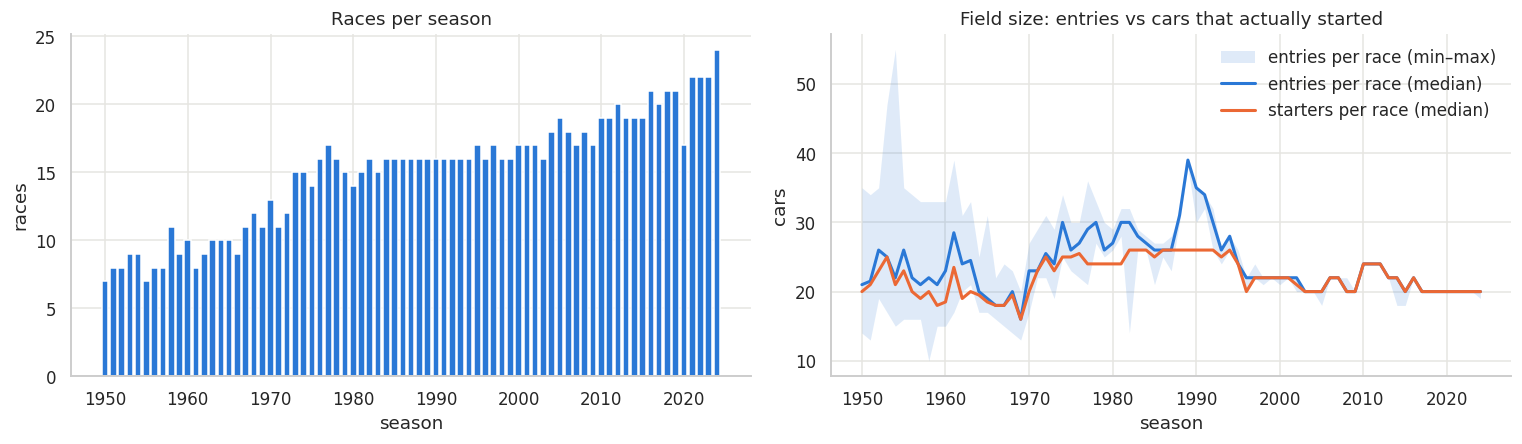

races per season: {1950: 7, 1970: 13, 1990: 16, 2010: 19, 2024: 24}


In [14]:
races_per_season = raw["races"].groupby("year").size()
field = eda.groupby(["year", "raceId"]).size().groupby("year").agg(["median", "min", "max"])
starters = eda[~eda["never_started"]].groupby(["year", "raceId"]).size().groupby("year").median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
ax1.bar(races_per_season.index, races_per_season.values, color=BLUE, width=0.8)
ax1.set(title="Races per season", xlabel="season", ylabel="races")
ax2.fill_between(field.index, field["min"], field["max"], color=BLUE, alpha=0.15, lw=0,
                 label="entries per race (min–max)")
ax2.plot(field.index, field["median"], color=BLUE, lw=2, label="entries per race (median)")
ax2.plot(starters.index, starters.values, color=ORANGE, lw=2, label="starters per race (median)")
ax2.set(title="Field size: entries vs cars that actually started", xlabel="season", ylabel="cars")
ax2.legend(frameon=False)
plt.tight_layout(); plt.show()
print("races per season:", races_per_season.loc[[1950, 1970, 1990, 2010, 2024]].to_dict())

**Reading.** Seasons grew from 7 races (1950) to 24 (2024). The field (cars per race) was large and very
uneven until the mid-1990s: in the late 1980s up to ~39 cars entered per race but only 26 could start, which
is why entries and starters split apart. The 55-entry spike in 1954 is the Indianapolis 500. Since ~1996
entries = starters ≈ 20–24, the same shape as the 2022–24 test seasons.

### 2.3 Podium rate per era

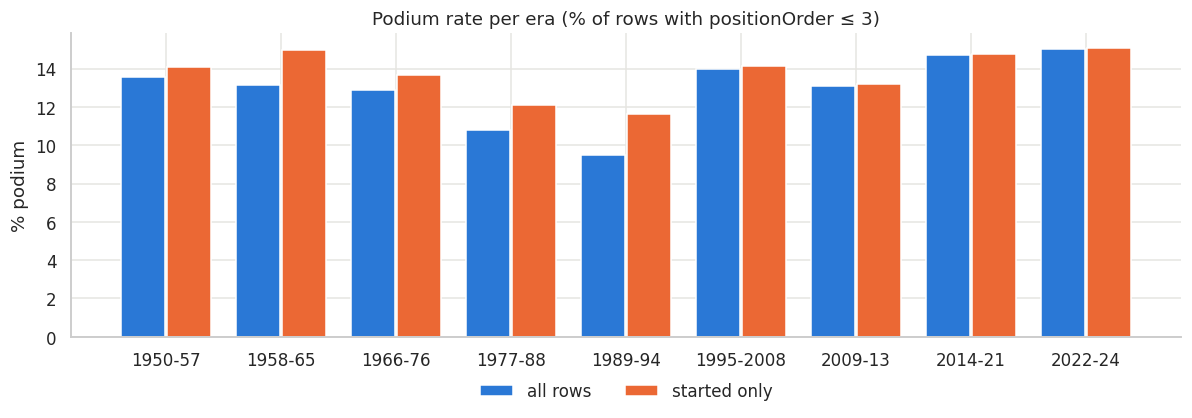

,all rows,started only,never-started share,rows
era,,,,
1950-57,13.6%,14.1%,3.6%,"1,571"
1958-65,13.1%,15.0%,12.5%,"1,768"
1966-76,12.9%,13.7%,5.8%,"3,237"
1977-88,10.8%,12.1%,11.0%,"5,234"
1989-94,9.5%,11.6%,18.3%,"3,035"
1995-2008,14.0%,14.1%,1.2%,"5,138"
2009-13,13.1%,13.2%,0.7%,"2,150"
2014-21,14.7%,14.8%,0.6%,"3,267"
2022-24,15.0%,15.1%,0.5%,"1,359"


In [15]:
base = pd.DataFrame({
    "all rows": eda.groupby("era", observed=True)["podium"].mean(),
    "started only": eda[~eda["never_started"]].groupby("era", observed=True)["podium"].mean(),
    "never-started share": eda.groupby("era", observed=True)["never_started"].mean(),
    "rows": eda.groupby("era", observed=True).size(),
})
x = np.arange(len(base))
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x - 0.2, base["all rows"] * 100, width=0.38, color=BLUE, label="all rows")
ax.bar(x + 0.2, base["started only"] * 100, width=0.38, color=ORANGE, label="started only")
ax.set_xticks(x, base.index)
ax.set(title="Podium rate per era (% of rows with positionOrder ≤ 3)", ylabel="% podium")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()
base.style.format({"all rows": "{:.1%}", "started only": "{:.1%}", "never-started share": "{:.1%}", "rows": "{:,}"})

**Reading.** Podium rate is 13–15% of rows in most eras but drops to 10.8% (1977–88) and 9.5% (1989–94),
the eras with the most never-started entries (11% and 18% of rows). Counting only starters, every era is
between 11.6% and 15.1%. 2022–24 (the likely test set) is 15.1%. The target is imbalanced: ~1 positive per
6–7 rows, so accuracy alone is misleading.

### 2.4 Podium rows per race

In [16]:
podiums_per_race = eda[eda["podium"]].groupby("raceId").size()
print("races by number of podium rows:", podiums_per_race.value_counts().sort_index().to_dict())
odd = podiums_per_race[podiums_per_race != 3].index
(eda[eda["raceId"].isin(odd)].groupby(["year", "name"])
    .agg(podium_rows=("podium", "sum"),
         tied_positionOrder=("positionOrder", lambda s: int(s.duplicated().sum()))))

races by number of podium rows: {3: 1107, 4: 16, 5: 1, 7: 1}


podium_rows  tied_positionOrder
year name                                                 
1950 Italian Grand Prix              4                   2
1951 French Grand Prix               5                   3
     Indianapolis 500                4                   1
     Italian Grand Prix              4                   1
1953 Dutch Grand Prix                4                   1
     Indianapolis 500                4                  14
1954 German Grand Prix               4                   1
     Italian Grand Prix              4                   1
1955 Argentine Grand Prix            7                  14
     Indianapolis 500                4                   2
     Monaco Grand Prix               4                   3
1956 Argentine Grand Prix            4                   3
     Belgian Grand Prix              4                   1
     British Grand Prix              4                   2
     Italian Grand Prix              4                   4
     Monaco Grand Prix               4                   3
1957 British Grand Prix              4                   3
1960 Argentine Grand Prix            4                   1

**Reading.** 1,107 of 1,125 races have exactly 3 podium rows. 18 races (1950–1960) have 4, 5 or 7, because in a
shared drive every driver of a podium car got the same `positionOrder` (123 tied `positionOrder` values in
total). This is the same shared-drive problem as the duplicate (raceId, driverId) rows, seen from the target's
side; it is handled with the grain fix in §3.

### 2.5 How races end (status)

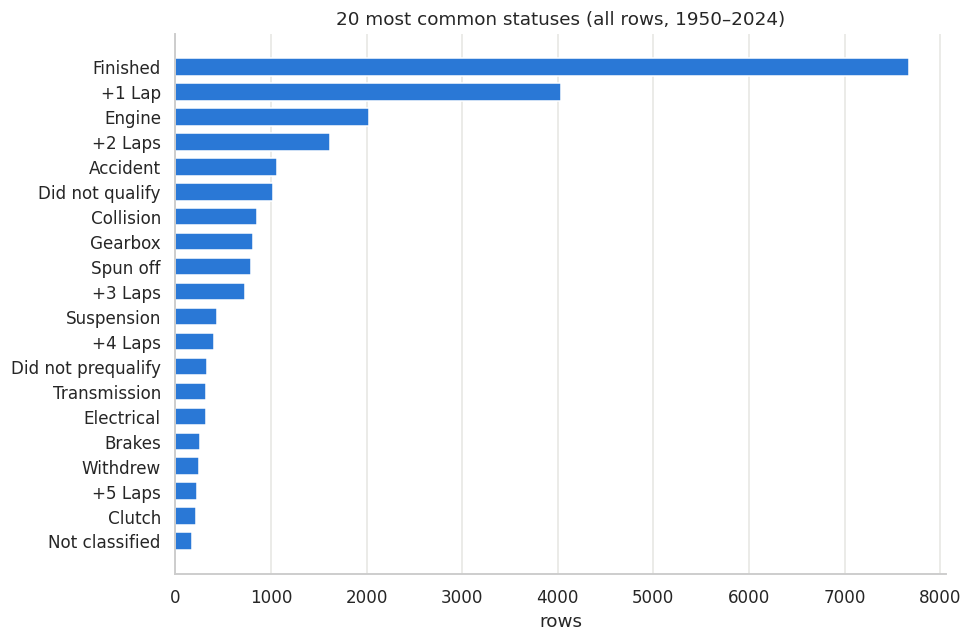

137 distinct statuses; top 20 cover 88.0% of rows


In [17]:
top_status = eda["status"].value_counts().head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_status.index, top_status.values, color=BLUE, height=0.7)
ax.set(title="20 most common statuses (all rows, 1950–2024)", xlabel="rows")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"{eda['status'].nunique()} distinct statuses; top 20 cover "
      f"{eda['status'].value_counts().head(20).sum() / len(eda):.1%} of rows")

**Reading.** 137 distinct statuses; the top 20 cover 88% of rows. "Finished" and "+N Laps" (finished but lapped)
are the most common outcomes; mechanical failures (Engine, Gearbox, Suspension, Transmission, Electrical,
Brakes, Clutch) and incidents (Accident, Collision, Spun off) follow. "Did not qualify", "Did not prequalify"
and "Withdrew" are not race outcomes: those cars never started. Status is post-race, so it is never a
feature; it is needed for Question 3 and for identifying never-started rows.

### 2.6 What `grid = 0` means

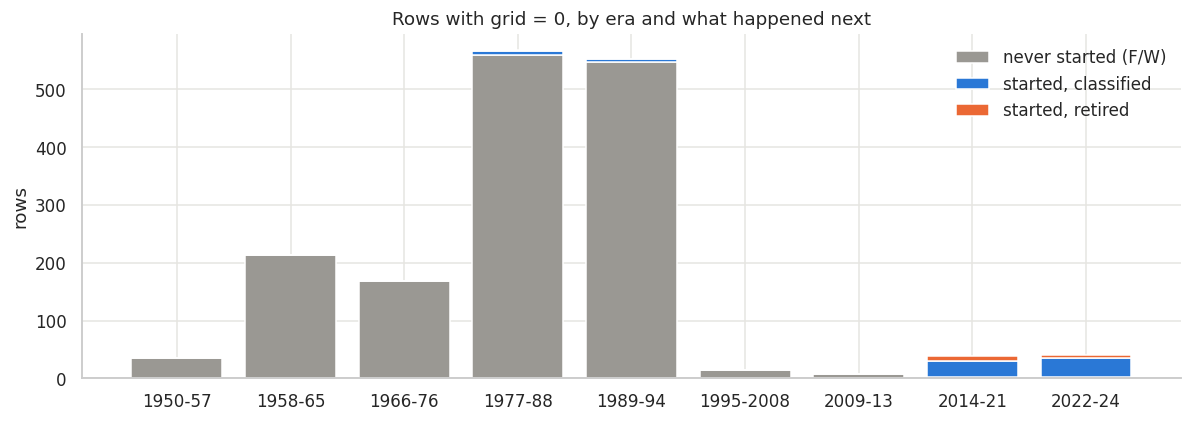

podiums from grid = 0: 0


outcome,never started (F/W),"started, classified","started, retired"
era,,,
1950-57,35,0,0
1958-65,213,0,0
1966-76,168,0,0
1977-88,560,7,1
1989-94,548,5,0
1995-2008,14,1,0
2009-13,7,0,0
2014-21,3,27,9
2022-24,3,33,4


In [18]:
g0 = eda[eda["grid"] == 0].copy()
g0["outcome"] = np.select(
    [g0["never_started"], g0["positionText"] == "R"],
    ["never started (F/W)", "started, retired"], default="started, classified")
g0_table = pd.crosstab(g0["era"], g0["outcome"]).reindex(ERA_LABELS, fill_value=0)
g0_table = g0_table[["never started (F/W)", "started, classified", "started, retired"]]
fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(g0_table))
for col, color in zip(g0_table.columns, [GREY, BLUE, ORANGE]):
    ax.bar(g0_table.index, g0_table[col], bottom=bottom, color=color, label=col,
           edgecolor="white", linewidth=1)
    bottom += g0_table[col].values
ax.set(title="Rows with grid = 0, by era and what happened next", ylabel="rows")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print("podiums from grid = 0:", int(g0["podium"].sum()))
g0_table

**Reading.** `grid = 0` has two different meanings depending on the era. Before 2014, 1,545 of 1,559 grid-0 rows
are cars that never started (failed to qualify or withdrew). From 2014 on, 73 of 79 grid-0 cars started and
60 were classified: these are **pit-lane starts**. No grid-0 car ever reached the podium. Left as the number 0,
it would look *better than pole position(Grid 1)*, so it must be recoded in §3.

### 2.7 Duplicate (raceId, driverId) rows by season

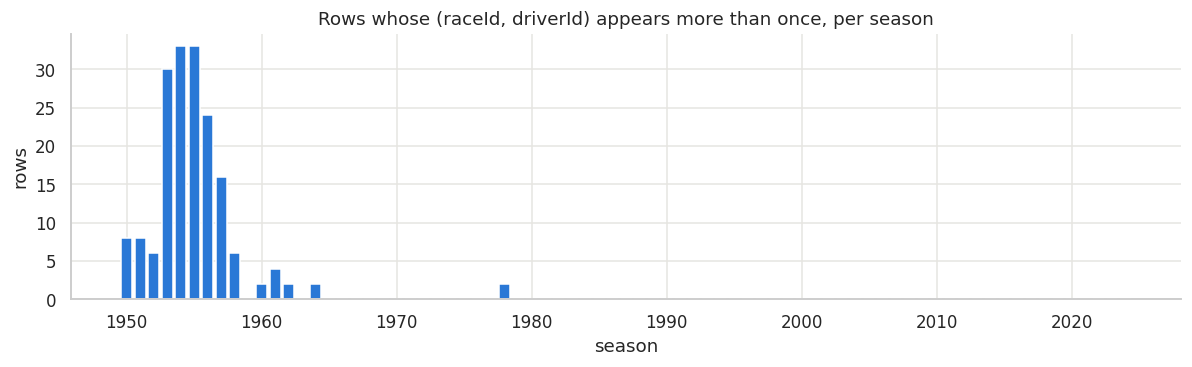

176 rows, 85 pairs, 42 races; 164 rows from 1950–1958


In [19]:
dup_rows = eda[eda.duplicated(["raceId", "driverId"], keep=False)]
dup_by_year = dup_rows.groupby("year").size().reindex(range(1950, 2025), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(dup_by_year.index, dup_by_year.values, color=BLUE, width=0.8)
ax.set(title="Rows whose (raceId, driverId) appears more than once, per season",
       xlabel="season", ylabel="rows")
plt.tight_layout(); plt.show()
print(f"{len(dup_rows)} rows, {dup_rows.groupby(['raceId', 'driverId']).ngroups} pairs, "
      f"{dup_rows['raceId'].nunique()} races; "
      f"{(dup_rows['year'] <= 1958).sum()} rows from 1950–1958")

**Reading.** 176 rows share a (raceId, driverId) with another row: 85 pairs in 42 races. 164 of the 176 rows are from
1950–1958 (shared drives), the rest are single cases up to 1978. Nothing after 1978. The grain
"one row per (raceId, driverId)" therefore only fails in early seasons; the rule for which row to keep is
set in §3.3.

### 2.8 Missing values per column per season
Results joined with qualifying, starters only: what a model row would be missing, season by season. Darker = more missing.

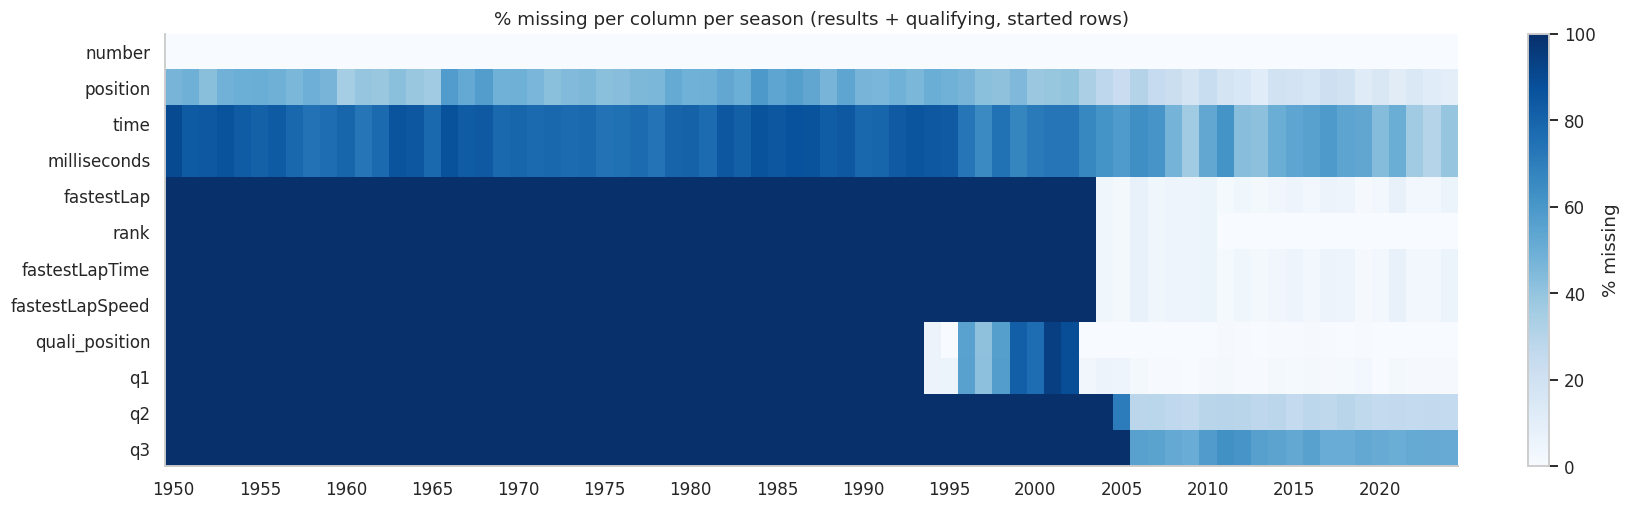

In [20]:
# results + qualifying (left join on race + driver), started rows only, so the map shows
# what a model row would be missing, season by season
miss_frame = (eda[~eda["never_started"]]
              .merge(raw["qualifying"][["raceId", "driverId", "position", "q1", "q2", "q3"]]
                     .rename(columns={"position": "quali_position"}),
                     on=["raceId", "driverId"], how="left"))
MISS_COLS = ["number", "position", "time", "milliseconds", "fastestLap", "rank",
             "fastestLapTime", "fastestLapSpeed", "quali_position", "q1", "q2", "q3"]
miss_by_season = miss_frame.groupby("year")[MISS_COLS].apply(lambda t: t.isna().mean() * 100).T

fig, ax = plt.subplots(figsize=(15, 4.8))
im = ax.imshow(miss_by_season.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
years = miss_by_season.columns
ticks = [i for i, y in enumerate(years) if y % 5 == 0]
ax.set_xticks(ticks, [years[i] for i in ticks])
ax.set_yticks(range(len(MISS_COLS)), MISS_COLS)
ax.grid(False)
ax.set_title("% missing per column per season (results + qualifying, started rows)")
fig.colorbar(im, ax=ax, label="% missing", fraction=0.025)
plt.tight_layout(); plt.show()

**Reading.** Missingness follows the season, not chance. Fastest-lap columns are missing for every season before
2004 (not recorded). `quali_position`/`q1` are missing before 1994, patchy 1996–2002, and present from 2003. `q2` exists
from 2005–06 and `q3` from 2006, and are then missing for ~28% / ~53% of drivers each season (knocked out in Q1/Q2).
`position` and `time` are missing for non-classified drivers. Only the qualifying columns are pre-race;
the others are post-race and will be dropped from features anyway.

### 2.9 Qualifying coverage per season

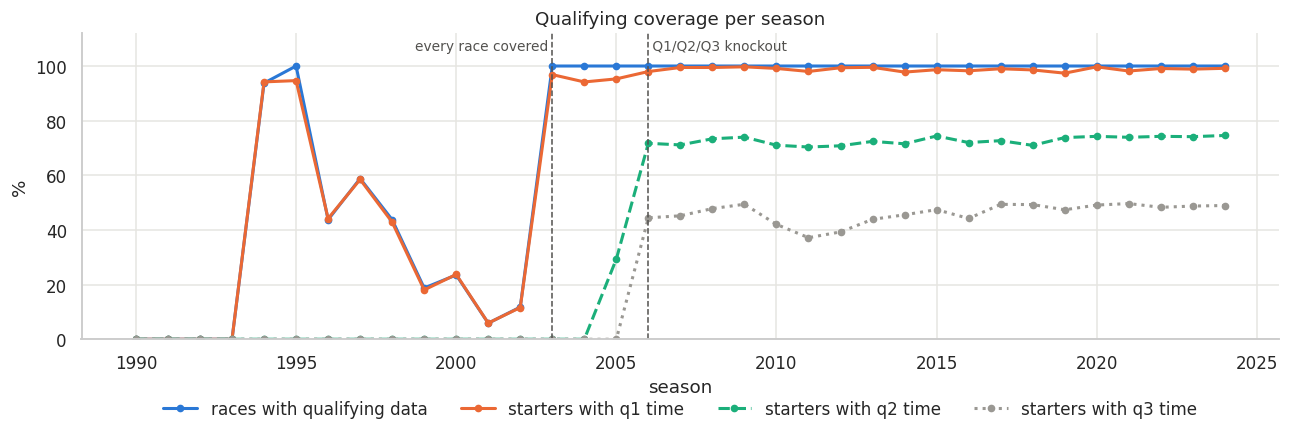

,races with qualifying data,starters with q1 time,starters with q2 time,starters with q3 time
year,,,,
1993,0.0,0.0,0.0,0.0
1994,94.0,94.0,0.0,0.0
1995,100.0,95.0,0.0,0.0
1996,44.0,44.0,0.0,0.0
1997,59.0,58.0,0.0,0.0
1998,44.0,43.0,0.0,0.0
1999,19.0,18.0,0.0,0.0
2000,24.0,24.0,0.0,0.0
2001,6.0,6.0,0.0,0.0


In [21]:
races_q = raw["races"].assign(has_q=raw["races"]["raceId"].isin(raw["qualifying"]["raceId"]))
q_cov = pd.DataFrame({
    "races with qualifying data": races_q.groupby("year")["has_q"].mean() * 100,
    "starters with q1 time": miss_frame.groupby("year")["q1"].apply(lambda s: s.notna().mean() * 100),
    "starters with q2 time": miss_frame.groupby("year")["q2"].apply(lambda s: s.notna().mean() * 100),
    "starters with q3 time": miss_frame.groupby("year")["q3"].apply(lambda s: s.notna().mean() * 100),
}).loc[1990:]
fig, ax = plt.subplots(figsize=(12, 4.2))
for col, color, style in zip(q_cov.columns, [BLUE, ORANGE, AQUA, GREY], ["-", "-", "--", ":"]):
    ax.plot(q_cov.index, q_cov[col], color=color, lw=2, ls=style, marker="o", ms=4, label=col)
for yr, txt, ha in [(2003, "every race covered ", "right"), (2006, " Q1/Q2/Q3 knockout", "left")]:
    ax.axvline(yr, color="#52514e", lw=1, ls="--")
    ax.text(yr, 106, txt, fontsize=9, color="#52514e", ha=ha)
ax.set(title="Qualifying coverage per season", xlabel="season", ylabel="%", ylim=(0, 112))
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout(); plt.show()
q_cov.loc[1993:2007].round(0)

**Reading.** Qualifying exists from 1994, but 1996–2002 cover only 6–59% of races (2001: 1 of 17 races). From 2003 every
race has qualifying data and 94–100% of starters have a q1 time. Q2/Q3 times appear with the knockout format in
2006 (2005 is a transition year), after which ~72% of starters have q2 and ~47% q3, every season.

### 2.10 Candidate training windows
Started rows from each candidate start season up to 2019 (the planned end of training).

In [22]:
cands = {"all seasons (1950+)": 1950, "qualifying exists (1994+)": 1994,
         "every race has qualifying (2003+)": 2003, "knockout format (2006+)": 2006}
started_q = miss_frame.assign(has_q=miss_frame["quali_position"].notna())
window = pd.DataFrame({
    name: {
        "train rows (start..2019)": int(((started_q["year"] >= y0) & (started_q["year"] <= 2019)).sum()),
        "train podiums": int(started_q.loc[(started_q["year"] >= y0) & (started_q["year"] <= 2019), "podium"].sum()),
        "rows with qualifying %": round(100 * started_q.loc[started_q["year"] >= y0, "has_q"].mean(), 1),
        "rows with q3 %": round(100 * started_q.loc[started_q["year"] >= y0, "q3"].notna().mean(), 1),
    } for name, y0 in cands.items()
}).T.astype({"train rows (start..2019)": int, "train podiums": int})
window

,train rows (start..2019),train podiums,rows with qualifying %,rows with q3 %
all seasons (1950+),22928,3076,41.6,14.5
qualifying exists (1994+),10093,1410,85.3,29.6
every race has qualifying (2003+),6783,963,99.8,40.7
knockout format (2006+),5744,804,99.7,46.0


**Reading.** Starting earlier gives more rows (22,928 from 1950 vs 6,783 from 2003) but rows that look less like the
validation and test seasons: only 41.6% of 1950+ rows have qualifying data, against 99.8% from 2003.

### 2.11 Window experiment: does the start season change validation scores?
Quick models (logistic regression, gradient boosting) on quick leakage-safe features (grid, qualifying, recent form with
`shift(1)`), trained from five start seasons and scored on three **validation** periods (never the test seasons).
Validation races are resampled 1,000 times to see whether the 1994 vs 2003 gap is real.

In [23]:
# Quick, leakage-safe features only (grid, qualifying, recent form). Validation seasons only, never test.
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score
from IPython.display import display

w = (eda[~eda["never_started"]]
     .sort_values(["raceId", "driverId", "grid"]).drop_duplicates(["raceId", "driverId"])
     .merge(raw["races"][["raceId", "date"]], on="raceId")
     .merge(raw["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "qpos"}),
            on=["raceId", "driverId"], how="left"))
w["date"] = pd.to_datetime(w["date"])
w = w.sort_values(["date", "raceId"]).reset_index(drop=True)
w["y"] = w["podium"].astype(int)
w["field"] = w.groupby("raceId")["driverId"].transform("size")
w["pit"] = (w["grid"] == 0).astype(int)
w["grid_c"] = np.where(w["grid"] == 0, w["field"], w["grid"])
w["grid_n"] = w["grid_c"] / w["field"]
w["has_q"] = w["qpos"].notna().astype(int)
w["qpos_f"] = w["qpos"].fillna(w["grid_c"])
for key, col, n in [("drv", "driverId", 5), ("con", "constructorId", 10)]:   # shift(1): past races only
    w[f"{key}_pod"] = (w.groupby(col)["y"].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())
                       .fillna(0))
w["drv_n"] = w.groupby("driverId").cumcount()
FEATS = ["grid_c", "grid_n", "pit", "qpos_f", "has_q", "drv_pod", "con_pod", "drv_n"]

FOLDS = {"val 2016-17": (2015, [2016, 2017]), "val 2018-19": (2017, [2018, 2019]),
         "val 2020-21": (2019, [2020, 2021])}
STARTS = [1950, 1980, 1994, 2003, 2006]
rows, preds = [], {}
for fold, (last_train, val_years) in FOLDS.items():
    va = w[w["year"].isin(val_years)]
    for start in STARTS:
        tr = w[(w["year"] >= start) & (w["year"] <= last_train)]
        models = {"logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                  "gbm": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                        max_iter=300, random_state=SEED)}
        for name, m in models.items():
            p = m.fit(tr[FEATS], tr["y"]).predict_proba(va[FEATS])[:, 1]
            preds[(fold, start, name)] = p
            rows.append({"model": name, "fold": fold, "start": start,
                         "PR-AUC": average_precision_score(va["y"], p)})
window_scores = pd.DataFrame(rows).pivot_table(index=["model", "fold"], columns="start", values="PR-AUC")
display(window_scores.round(3))

# Is 1994 vs 2003 a real difference? Resample validation RACES 1000 times
rng = np.random.default_rng(SEED)
boot = []
for fold, (last_train, val_years) in FOLDS.items():
    va = w[w["year"].isin(val_years)].reset_index(drop=True)
    by_race = {r: g.index.values for r, g in va.groupby("raceId")}
    race_ids = np.array(list(by_race))
    for name in ["logreg", "gbm"]:
        a, b = preds[(fold, 1994, name)], preds[(fold, 2003, name)]
        diffs = []
        for _ in range(1000):
            idx = np.concatenate([by_race[r] for r in rng.choice(race_ids, len(race_ids))])
            y = va["y"].values[idx]
            diffs.append(average_precision_score(y, a[idx]) - average_precision_score(y, b[idx]))
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        boot.append({"fold": fold, "model": name, "1994 − 2003": np.mean(diffs),
                     "95% CI low": lo, "95% CI high": hi, "CI includes 0": lo <= 0 <= hi})
pd.DataFrame(boot).round(3)

start                1950   1980   1994   2003   2006
model  fold                                          
gbm    val 2016-17  0.756  0.757  0.758  0.751  0.750
       val 2018-19  0.706  0.710  0.665  0.691  0.690
       val 2020-21  0.707  0.710  0.707  0.708  0.692
logreg val 2016-17  0.725  0.725  0.726  0.725  0.731
       val 2018-19  0.688  0.690  0.692  0.691  0.699
       val 2020-21  0.705  0.713  0.717  0.720  0.718

,fold,model,1994 − 2003,95% CI low,95% CI high,CI includes 0
0,val 2016-17,logreg,0.001,-0.008,0.009,True
1,val 2016-17,gbm,0.007,-0.011,0.025,True
2,val 2018-19,logreg,0.001,-0.006,0.008,True
3,val 2018-19,gbm,-0.026,-0.049,-0.001,False
4,val 2020-21,logreg,-0.003,-0.011,0.005,True
5,val 2020-21,gbm,-0.001,-0.020,0.021,True


**Reading.** Across 3 validation periods and 2 models, no start season wins consistently (gradient boosting: 1980 best
twice, 1950 once; logistic regression: 2006 best twice, 2003 once). Every 1994 − 2003 difference has a 95% bootstrap
interval that includes 0. The training window does not measurably change validation PR-AUC, so it is chosen on data grounds.

### 2.12 Training-window decision: seasons 2003+
**Decision:** modeling rows use seasons 2003 onward (train 2003–2019, validation 2020–21, test 2022–24).
- **Qualifying-coverage drift (warned about in the brief):** qualifying covers 94–100% of races in 1994–95,
  only 6–59% in 1996–2002, then 100% from 2003 (§2.9). Any window starting before 2003 mixes rows where
  qualifying exists with rows where it is missing *because of the season*, and the model can learn that
  pattern even though validation and test never have it. From 2003, coverage is flat and matches val/test.
- **Scores don't argue otherwise:** start season changes validation PR-AUC by amounts within noise
  (§2.11: 3 folds, 2 models, all bootstrap CIs of 1994 − 2003 include 0).
- **What we keep:** 6,783 training rows, 963 podiums (§2.10). Seasons before 2003 stay in the data:
  form features for a 2003 race still look back at earlier races, and stage B's DE questions use all seasons.

## 3. Cleaning
All cleaning runs on the working copies in `df`; `raw` is never modified. Rules followed in every step:
1. **Every fix is code**, so Run All reproduces it.
2. **Count before and after** each step (the tables in §3.2–3.5 log every removed row and why).
3. **Order matters:** first fix types (so comparisons work), then remove rows that should not be there,
   then fix the grain (one row per race and driver), then recode sentinel values.
4. **The training window is not applied here.** Clean tables keep every season, because history features and the
   data-engineering questions need earlier races. The window is applied only when building the modeling table (§5).

Each decision below is logged in `decisions.md` with the evidence shown here.

### 3.1 Semantic typing: dates, lap times, nullable integers, text spellings
**Why.** The audit (§1.3) found numbers stored as text: dates (`"2009-03-29"`) and lap times (`"1:26.572"`).
As text they cannot be compared, subtracted or averaged: `"1:59.9" < "1:6.1"` is true for strings.
- **Dates** → `datetime`, so races can be sorted in time order (needed for every "previous races only" feature;
  `raceId` is *not* chronological).
- **Lap and session times** → seconds in new `*_s` columns (`q1_s`, `q2_s`, `q3_s`, …). The original text column is
  kept so the conversion can always be checked. Where the dataset also stores milliseconds (pit stops, lap times),
  we assert that our parsed seconds agree with them exactly.
- **Nullable integers** (`Int64`): columns such as `position` are whole numbers but became `float` only because they
  contain missing values. `Int64` keeps them integers and still allows missing.
- **Sentinel `rank = 0`**: the fastest-lap rank uses 0 for "no ranked lap", which is not a rank, so it becomes missing.
  (`rank` is post-race and never a feature; this only keeps the column honest.)

In [24]:
def to_seconds(s):
    """'1:26.572' -> 86.572, '22.534' -> 22.534, '2:05:05.152' -> 7505.152 (hours and minutes optional).
    Missing stays missing; anything else fails loudly."""
    parts = s.str.extract(r"^(?:(?:(\d+):)?(\d+):)?(\d+(?:\.\d+)?)$").astype(float)
    secs = parts[0].fillna(0) * 3600 + parts[1].fillna(0) * 60 + parts[2]
    unparsed = s.notna() & secs.isna()
    assert not unparsed.any(), f"unparsed values: {s[unparsed].unique()[:5]}"
    return secs

typing_log = []
def log_type(table, col, before, after, note=""):
    typing_log.append({"table": table, "column": col, "from": str(before), "to": str(after), "note": note})

# dates
for col in [c for c in df["races"].columns if c == "date" or c.endswith("_date")]:
    before = df["races"][col].dtype
    df["races"][col] = pd.to_datetime(df["races"][col], format="%Y-%m-%d")
    log_type("races", col, before, df["races"][col].dtype)
df["drivers"]["dob"] = pd.to_datetime(df["drivers"]["dob"], format="%Y-%m-%d")
log_type("drivers", "dob", "object", df["drivers"]["dob"].dtype)

# lap / session times stored as "m:ss.sss" text -> seconds (new *_s columns; the text column is kept)
for table, cols in {"qualifying": ["q1", "q2", "q3"],
                    "results": ["fastestLapTime"], "sprint_results": ["fastestLapTime"],
                    "pit_stops": ["duration"], "lap_times": ["time"]}.items():
    for col in cols:
        df[table][f"{col}_s"] = to_seconds(df[table][col])
        log_type(table, f"{col}_s", "text", "float64 seconds",
                 f"{df[table][col].notna().sum():,} values parsed")

# cross-check: the parsed durations must agree with the dataset's own millisecond columns
assert np.allclose(df["pit_stops"]["duration_s"], df["pit_stops"]["milliseconds"] / 1000, atol=0.001)
assert np.allclose(df["lap_times"]["time_s"], df["lap_times"]["milliseconds"] / 1000, atol=0.001)

# integer columns that became float only because they contain missing values -> nullable Int64
for table, cols in {"results": ["number", "position", "milliseconds", "fastestLap", "rank"],
                    "sprint_results": ["position", "milliseconds", "fastestLap"],
                    "drivers": ["number"]}.items():
    for col in cols:
        before = df[table][col].dtype
        assert (df[table][col].dropna() % 1 == 0).all(), f"{table}.{col} has fractions"
        df[table][col] = df[table][col].astype("Int64")
        log_type(table, col, before, "Int64")

# sentinel: results.rank (fastest-lap rank) uses 0 for "no ranked lap"; 0 is not a rank
rank0 = int((df["results"]["rank"] == 0).sum())
df["results"].loc[df["results"]["rank"] == 0, "rank"] = pd.NA
log_type("results", "rank", "0 sentinel", "<NA>", f"{rank0} zeros → missing")

display(pd.DataFrame(typing_log))

# check: no text column is still hiding numbers, except the ones kept as text on purpose
KEEP_AS_TEXT = {
    "positionText": "finishing position OR a letter code (R, D, W, ...); positionOrder holds the clean ranking",
    "time": "winner's total time OR a gap like '+5.478' (two meanings); milliseconds holds the number",
    "duration": "original text kept for checking; the number is in duration_s",
}
hiding = []
for name in TABLES:
    p = profile(df[name])
    for col, r in p.iterrows():
        if pd.api.types.is_datetime64_any_dtype(df[name][col]) or col in KEEP_AS_TEXT:
            continue
        if r["numeric-looking %"] is not None and r["numeric-looking %"] >= 50:
            hiding.append(f"{name}.{col}")
assert not hiding, f"text columns still hiding numbers: {hiding}"
print("no text column hides numbers; kept as text on purpose:", list(KEEP_AS_TEXT))

,table,column,from,to,note
0,races,date,object,datetime64[ns],
1,races,fp1_date,object,datetime64[ns],
2,races,fp2_date,object,datetime64[ns],
3,races,fp3_date,object,datetime64[ns],
4,races,quali_date,object,datetime64[ns],
5,races,sprint_date,object,datetime64[ns],
6,drivers,dob,object,datetime64[ns],
7,qualifying,q1_s,text,float64 seconds,"10,338 values parsed"
8,qualifying,q2_s,text,float64 seconds,"5,847 values parsed"
9,qualifying,q3_s,text,float64 seconds,"3,629 values parsed"


no text column hides numbers; kept as text on purpose: ['positionText', 'time', 'duration']


**Result.** 7 date columns → `datetime`; 7 text time columns → seconds (`q1_s`, `q2_s`, `q3_s`, `fastestLapTime_s` ×2,
`duration_s`, `time_s`), every value parsed; 9 float columns → `Int64`; 258 `rank = 0` → missing. Parsed pit-stop and lap
times match the dataset's own millisecond columns exactly (asserts pass). The parser also had to handle lap times over an
hour (`"2:05:05.152"`, laps run under a red flag): it fails loudly on any format it does not know, which is how this was found.

**Text spellings.** §1.8 found one value written two ways in two columns. We keep one spelling per value:
spaces at the ends of every text value are removed and HTML codes are turned back into characters (in every table,
so the same slip cannot hide anywhere else), and
the two synonyms are mapped to the spelling the rest of the column already uses (`"Argentine"`, `"USA"`).

In [25]:
# One spelling per value (decision 10, evidence §1.8).
# 1) remove spaces at the ends of every text value and turn HTML codes back into characters ("&amp;" -> "&")
# 2) merge the synonyms found in §1.8 into the spelling the rest of the table already uses
SPELLING_FIXES = {
    ("drivers", "nationality"): {"Argentinian": "Argentine"},    # 1 driver;  'Argentine' is used by 24 drivers
    ("circuits", "country"): {"United States": "USA"},           # 1 circuit; 'USA' is used by 11 circuits
}
text_log = []
for name in TABLES:
    for col in df[name].columns:
        s = df[name][col]
        if not pd.api.types.is_string_dtype(s):
            continue
        fixed = s.map(lambda v: html.unescape(v).strip() if isinstance(v, str) else v)
        n = int((s.notna() & (s != fixed)).sum())
        if n:
            df[name][col] = fixed
            text_log.append({"table": name, "column": col, "fix": "spaces at the ends / HTML codes", "rows changed": n})
for (name, col), mapping in SPELLING_FIXES.items():
    n = int(df[name][col].isin(list(mapping)).sum())
    df[name][col] = df[name][col].replace(mapping)
    text_log.append({"table": name, "column": col,
                     "fix": ", ".join(f"'{a}' → '{b}'" for a, b in mapping.items()), "rows changed": n})
display(pd.DataFrame(text_log))

# check: the §1.8 test now finds only first names, which belong to different people (e.g. Adrian Sutil, Adrián Campos)
left = spelling_issues(df)
assert set(zip(left["table"], left["column"])) <= {("drivers", "forename")}, left
assert not df["circuits"]["country"].eq("United States").any()
assert not df["drivers"]["nationality"].eq("Argentinian").any()

# which seasons does this touch?
races_y = df["races"][["raceId", "year", "circuitId"]]
touched = pd.concat([
    df["results"].merge(races_y, on="raceId").loc[lambda t: t["driverId"].isin(
        raw["drivers"].loc[raw["drivers"]["nationality"].str.strip() == "Argentinian", "driverId"]), "year"],
    races_y.loc[races_y["circuitId"].isin(
        raw["circuits"].loc[raw["circuits"]["country"] == "United States", "circuitId"]), "year"],
])
print("seasons touched by the synonym fixes:", sorted(touched.unique()))


,table,column,fix,rows changed
0,constructors,name,spaces at the ends / HTML codes,1
1,drivers,nationality,spaces at the ends / HTML codes,1
2,drivers,nationality,'Argentinian' → 'Argentine',1
3,circuits,country,'United States' → 'USA',1


seasons touched by the synonym fixes: [np.int64(2023), np.int64(2024)]


**Result.** 1 driver's nationality loses its trailing space and becomes `"Argentine"`; 1 circuit's country becomes
`"USA"`; 1 constructor name gets its `&` back. Re-running the §1.8 check on `df` finds only the first names of different people (assert passes).

**Does this change our model?** Almost certainly not, because of our split. Both fixes touch only the **2023–2024**
seasons (Colapinto's 9 starts in 2024, the 2 Las Vegas races), which are in the **test** set. Training (2003–2019) and
validation (2020–2021) rows are identical before and after. The fix still matters for the home-race question (Q2), where
it turns one 2023 result into a home race (Logan Sargeant, American, at Las Vegas), and for a `home_race` feature, if
stage C builds one. Fixing it now keeps the test seasons consistent with the rest of the data.

### 3.2 Row filters: races without results, the Indianapolis 500, cars that never started
**Why each filter.**
- **(a) Races without results**: §1.7 found none in this snapshot. The check stays so a refreshed dataset would be caught.
- **(b) The Indianapolis 500 (1950–1960)**: counted for the championship then, but it was an American race run to
  different rules, with its own drivers who almost never entered another Grand Prix. It inflates field sizes
  (55 entries in 1954, §2.2) and would distort any "home race" analysis for American drivers. All its rows are
  removed from every table that has a `raceId`.
- **(c) Entries that never took the start**: `positionText` F (failed to qualify / pre-qualify) or W (withdrew) with
  **0 laps completed**. These cars were not in the race, so they cannot be "predicted" before it: their outcome
  (no podium) is already known from the fact that they have no grid slot. Keeping them would add free correct
  answers and inflate every metric (§2.3: they are 18% of 1989–94 rows). The 0-laps condition keeps the handful of
  F/W rows that actually raced some laps. Removed rows are kept aside in `never_started`, not lost.

In [26]:
filter_log = []
def log_filter(step, table, before, after, reason):
    filter_log.append({"step": step, "table": table, "rows before": before, "rows after": after,
                       "removed": before - after, "reason": reason})

# (a) races without results: checked in §1.7, none in this snapshot; kept as a guard for a refreshed dataset
no_res = ~df["races"]["raceId"].isin(df["results"]["raceId"])
n = len(df["races"]); df["races"] = df["races"][~no_res].copy()
log_filter("a", "races", n, len(df["races"]), "race listed with no results rows")

# (b) the Indianapolis 500 (1950-1960): a US race on a different calendar, almost no F1 regulars
indy_ids = df["races"].loc[df["races"]["name"].str.contains("Indianapolis"), "raceId"]
print(f"Indianapolis 500: {len(indy_ids)} races,",
      sorted(df["races"].loc[df["races"]["raceId"].isin(indy_ids), "year"]))
for name in TABLES:
    if "raceId" in df[name].columns:
        n = len(df[name]); df[name] = df[name][~df[name]["raceId"].isin(indy_ids)].copy()
        if n != len(df[name]):
            log_filter("b", name, n, len(df[name]), "Indianapolis 500")

# (c) entries that never took the start: failed to (pre-)qualify (F) or withdrew (W) and completed 0 laps
res = df["results"]
never = res["positionText"].isin(["F", "W"]) & (res["laps"] == 0)
print("F/W rows that still completed laps (kept as starters):",
      int((res["positionText"].isin(["F", "W"]) & (res["laps"] > 0)).sum()))
print("never-started rows on the podium:", int((never & (res["positionOrder"] <= 3)).sum()))
never_started = res[never].copy()          # kept aside, not lost
n = len(res); df["results"] = res[~never].copy()
log_filter("c", "results", n, len(df["results"]), "never started (F/W, 0 laps)")

pd.DataFrame(filter_log)

Indianapolis 500: 11 races, [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960]
F/W rows that still completed laps (kept as starters): 6
never-started rows on the podium: 0


,step,table,rows before,rows after,removed,reason
0,a,races,1125,1125,0,race listed with no results rows
1,b,constructor_results,12625,12604,21,Indianapolis 500
2,b,constructor_standings,13391,13365,26,Indianapolis 500
3,b,driver_standings,34863,34194,669,Indianapolis 500
4,b,races,1125,1114,11,Indianapolis 500
5,b,results,26759,26354,405,Indianapolis 500
6,c,results,26354,24656,1698,"never started (F/W, 0 laps)"


**Result.** No races without results. Indianapolis 500: 11 races (1950–1960) removed from 5 tables (405 results rows).
Never started: 1,698 results rows removed (6 F/W rows that completed laps are kept as starters); none of the removed rows
was on the podium, which confirms they carry no information about who finishes in the top 3.

### 3.3 Grain fix: one row per (raceId, driverId)
**Why.** The model needs exactly one row per driver per race (§1.5 found 85 duplicated pairs). The duplicates are
1950s–60s **shared drives**: a driver whose car broke took over a team-mate's car, and each car got its own row.
**Rule:** keep the row of the car the driver started in, taken as the row with the **best (lowest) grid slot**; ties
go to the lowest `resultId`. Team leaders usually took over a slower team-mate's car that started further back, so
the best grid slot is the driver's own car. We deliberately **do not** use "keep the best finishing position":
that would pick rows by the race outcome, which is the target. None of these rows are in the modeling window
(2003+), so this choice cannot change the model; it keeps the all-season tables consistent for later analysis.

In [27]:
res = df["results"]
dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask].merge(df["races"][["raceId", "year"]], on="raceId")
print(f"before: {len(res):,} rows, {dup_mask.sum()} rows in "
      f"{dups.groupby(['raceId', 'driverId']).ngroups} duplicated pairs, "
      f"seasons {dups['year'].min()}–{dups['year'].max()}")
print("pairs where every row has a real grid slot:",
      int(dups.groupby(["raceId", "driverId"])["grid"].apply(lambda g: (g > 0).all()).sum()))

# keep the car the driver started in = the row with the best (lowest) grid slot; tie -> lowest resultId.
# Only pre-race information (grid) decides; finishing position is never used to pick the row.
n = len(res)
df["results"] = (res.assign(_g=res["grid"].replace(0, 999))
                    .sort_values(["raceId", "driverId", "_g", "resultId"])
                    .drop_duplicates(["raceId", "driverId"], keep="first")
                    .drop(columns="_g")
                    .sort_values("resultId").reset_index(drop=True))
log_filter("d", "results", n, len(df["results"]), "duplicate (raceId, driverId): kept lowest grid")
assert not df["results"].duplicated(["raceId", "driverId"]).any()
print(f"after: {len(df['results']):,} rows, (raceId, driverId) unique")

before: 24,656 rows, 125 rows in 61 duplicated pairs, seasons 1950–1964
pairs where every row has a real grid slot: 61
after: 24,592 rows, (raceId, driverId) unique


**Result.** After the filters, 61 duplicated pairs (125 rows) remain, all in 1950–1964, and in every pair both rows
have a real grid slot, so the grid rule always applies. 64 rows removed; `(raceId, driverId)` is now unique (assert passes).

### 3.4 grid = 0: pit-lane starts go to the back of the grid, with a flag
**Why.** §2.6 showed `grid = 0` means "started from the pit lane" in the modern data (and, before the never-started
filter, mostly "no grid slot"). Left as the number 0, a model reads it as *better than pole position*, when a
pit-lane start is the worst possible start. After the filters, the remaining grid-0 rows are cars that did start.
- `grid_clean`: a pit-lane starter is placed at the back, slot = number of starters in that race (`field_size`).
- `pit_lane_start`: a 0/1 flag, so the model can still tell "started last on the grid" from "started in the pit lane".
- The original `grid` column is kept unchanged for reference.

In [28]:
res = df["results"]
res["field_size"] = res.groupby("raceId")["driverId"].transform("size")   # cars that started this race
res["pit_lane_start"] = (res["grid"] == 0).astype(int)
# back of the grid = behind every car that took a grid slot (old races can have gaps in grid numbers)
back = np.maximum(res["field_size"], res.groupby("raceId")["grid"].transform("max"))
res["grid_clean"] = np.where(res["grid"] == 0, back, res["grid"])
g0 = res[res["grid"] == 0].merge(df["races"][["raceId", "year"]], on="raceId")
print(f"grid = 0 among starters: {len(g0)} rows ({(g0['year'] >= 2014).sum()} from 2014 on); "
      f"podiums among them: {int((g0['positionOrder'] <= 3).sum())}")
assert (res["grid_clean"] >= 1).all()
assert (res.loc[res["pit_lane_start"] == 1, "grid_clean"]
        >= res.loc[res["pit_lane_start"] == 1, "raceId"].map(res.groupby("raceId")["grid"].max())).all()
df["results"] = res
res[res["pit_lane_start"] == 1][["raceId", "driverId", "grid", "grid_clean", "field_size"]].head()

grid = 0 among starters: 87 rows (73 from 2014 on); podiums among them: 0


,raceId,driverId,grid,grid_clean,field_size
4270,220,58,0,22,22
6150,298,135,0,27,27
6748,321,112,0,27,27
6879,326,90,0,27,27
7688,364,161,0,27,27


**Result.** 87 starters had `grid = 0`, 73 of them from 2014 on (pit-lane starts); none reached the podium.
They are now at the back of the grid (`grid_clean`) with `pit_lane_start = 1`.

### 3.5 Cleaning summary
Rows per table before and after cleaning, and every step that removed rows.

In [29]:
cleaning_summary = pd.DataFrame({
    "raw rows": {n: len(raw[n]) for n in TABLES},
    "clean rows": {n: len(df[n]) for n in TABLES},
})
cleaning_summary["removed"] = cleaning_summary["raw rows"] - cleaning_summary["clean rows"]
display(pd.DataFrame(filter_log))
cleaning_summary[cleaning_summary["removed"] > 0]

,step,table,rows before,rows after,removed,reason
0,a,races,1125,1125,0,race listed with no results rows
1,b,constructor_results,12625,12604,21,Indianapolis 500
2,b,constructor_standings,13391,13365,26,Indianapolis 500
3,b,driver_standings,34863,34194,669,Indianapolis 500
4,b,races,1125,1114,11,Indianapolis 500
5,b,results,26759,26354,405,Indianapolis 500
6,c,results,26354,24656,1698,"never started (F/W, 0 laps)"
7,d,results,24656,24592,64,"duplicate (raceId, driverId): kept lowest grid"


,raw rows,clean rows,removed
constructor_results,12625,12604,21
constructor_standings,13391,13365,26
driver_standings,34863,34194,669
races,1125,1114,11
results,26759,24592,2167


**Result.** `results` goes from 26,759 to 24,592 rows (−2,167: Indianapolis 500 405, never started 1,698, duplicates 64);
`races` loses the 11 Indianapolis 500 races; the three standings/points tables lose only Indianapolis 500 rows.
All other tables are unchanged in rows (they gained typed columns in §3.1).

## 4. After-cleaning EDA
The key raw plots from §2, redrawn on the clean tables next to the raw version, to show what cleaning changed
and that nothing else moved.

### 4.1 Raw vs clean: podium rate per era and grid = 0

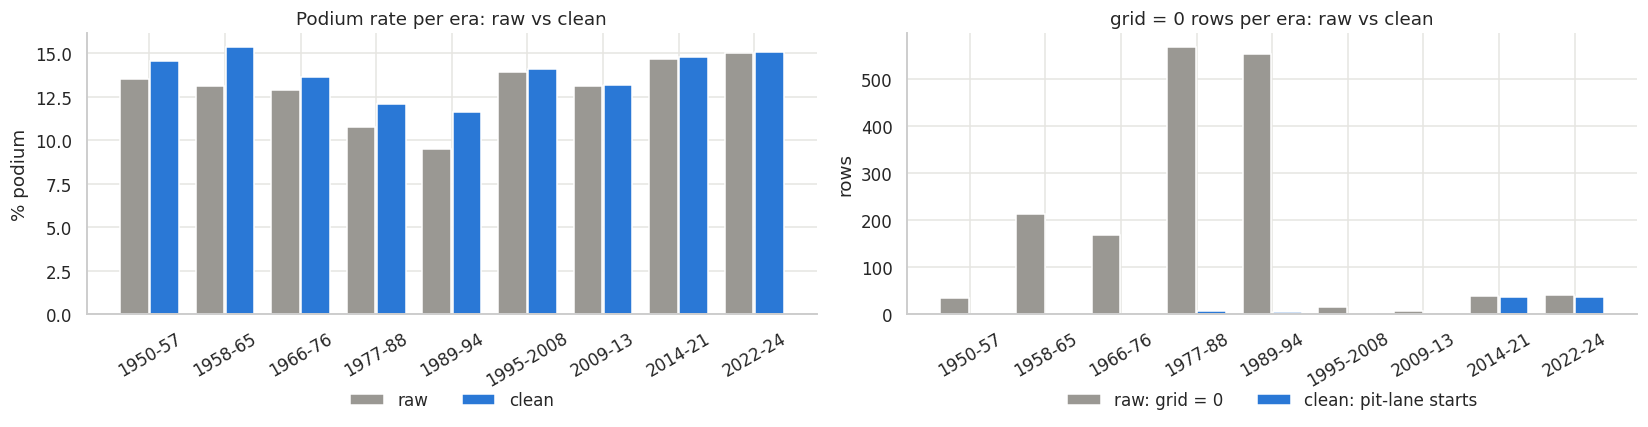

era,1950-57,1958-65,1966-76,1977-88,1989-94,1995-2008,2009-13,2014-21,2022-24
raw,13.6,13.1,12.9,10.8,9.5,14.0,13.1,14.7,15.0
clean,14.6,15.4,13.7,12.1,11.6,14.1,13.2,14.8,15.1


In [30]:
clean_eda = (df["results"].merge(df["races"][["raceId", "year"]], on="raceId"))
clean_eda["era"] = pd.cut(clean_eda["year"], bins=ERA_BINS, labels=ERA_LABELS)
clean_eda["podium"] = clean_eda["positionOrder"] <= 3

compare = pd.DataFrame({
    "raw": eda.groupby("era", observed=True)["podium"].mean() * 100,
    "clean": clean_eda.groupby("era", observed=True)["podium"].mean() * 100,
})
grid0 = pd.DataFrame({
    "raw (grid = 0)": eda[eda["grid"] == 0].groupby("era", observed=True).size(),
    "clean (pit-lane starts)": clean_eda[clean_eda["pit_lane_start"] == 1].groupby("era", observed=True).size(),
}).reindex(ERA_LABELS, fill_value=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.2))
x = np.arange(len(compare))
ax1.bar(x - 0.2, compare["raw"], width=0.38, color=GREY, label="raw")
ax1.bar(x + 0.2, compare["clean"], width=0.38, color=BLUE, label="clean")
ax1.set_xticks(x, compare.index, rotation=30)
ax1.set(title="Podium rate per era: raw vs clean", ylabel="% podium")
ax1.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.22))
x = np.arange(len(grid0))
ax2.bar(x - 0.2, grid0["raw (grid = 0)"], width=0.38, color=GREY, label="raw: grid = 0")
ax2.bar(x + 0.2, grid0["clean (pit-lane starts)"], width=0.38, color=BLUE, label="clean: pit-lane starts")
ax2.set_xticks(x, grid0.index, rotation=30)
ax2.set(title="grid = 0 rows per era: raw vs clean", ylabel="rows")
ax2.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout(); plt.show()
compare.round(1).T

**Reading.** Podium rate rises only in the eras where never-started rows were common (1977–88: 10.8% → 12.1%,
1989–94: 9.5% → 11.6%); from 1995 on it barely moves (the 2022–24 test era: 15.0% → 15.1%). `grid = 0` drops from
1,638 rows to 87, and almost all remaining ones are modern pit-lane starts.

### 4.2 Raw vs clean: rows per (raceId, driverId) and podium rows per race

In [31]:
check = pd.DataFrame({
    "raw": {"rows": len(eda),
            "duplicated (raceId, driverId) rows": int(eda.duplicated(["raceId", "driverId"], keep=False).sum()),
            "races with ≠ 3 podium rows": int((eda[eda["podium"]].groupby("raceId").size() != 3).sum()),
            "rows with grid = 0": int((eda["grid"] == 0).sum())},
    "clean": {"rows": len(clean_eda),
              "duplicated (raceId, driverId) rows": int(clean_eda.duplicated(["raceId", "driverId"], keep=False).sum()),
              "races with ≠ 3 podium rows": int((clean_eda[clean_eda["podium"]].groupby("raceId").size() != 3).sum()),
              "rows with grid = 0": int((clean_eda["grid"] == 0).sum())},
})
odd_clean = clean_eda[clean_eda["podium"]].groupby("raceId").size()
print("clean races with ≠ 3 podium rows are all shared drives, seasons:",
      sorted(int(y) for y in clean_eda.loc[clean_eda["raceId"].isin(odd_clean[odd_clean != 3].index), "year"].unique()))
check

clean races with ≠ 3 podium rows are all shared drives, seasons: [1951, 1955, 1956, 1957]


,raw,clean
rows,26759,24592
"duplicated (raceId, driverId) rows",176,0
races with ≠ 3 podium rows,18,5
rows with grid = 0,1638,87


**Reading.** Duplicated (raceId, driverId) rows: 176 → 0. `grid = 0`: 1,638 → 87. Races without exactly 3 podium
rows: 18 → 5, and the 5 left (1951–1957) are shared drives where two drivers of one podium car were both credited
with the result. That is how the sport scored them, so the rows stay; none of these seasons is in the modeling window.

### 4.3 Missingness in the modeling window after cleaning
Qualifying columns for the seasons the model will use (2003+), after cleaning: the coverage the model will actually see.

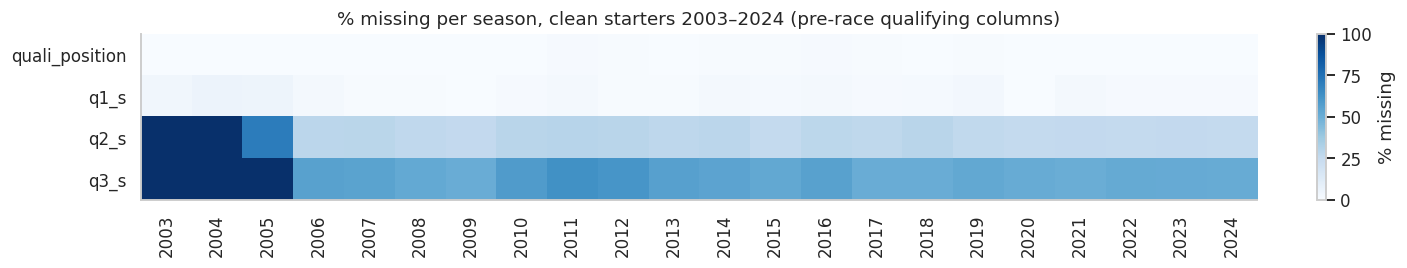

year,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
quali_position,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.9,0.6,0.0,0.5,0.5,1.1,0.5,0.0,0.5,0.0,0.2,0.0,0.0,0.0
q1_s,3.1,5.8,4.7,2.0,0.5,0.5,0.3,0.9,2.0,0.6,0.5,2.2,1.3,1.8,1.0,1.4,2.6,0.3,1.8,0.9,1.1,0.8
q2_s,100.0,100.0,70.6,28.3,28.9,26.6,26.0,29.0,29.6,29.2,27.6,28.5,25.6,28.0,27.3,29.0,26.2,25.7,26.1,25.7,25.9,25.4
q3_s,100.0,100.0,100.0,55.6,54.8,52.2,50.6,58.0,62.8,60.7,56.1,54.5,52.6,55.8,50.6,50.7,52.6,50.9,50.3,51.7,51.3,51.1


In [32]:
mw = (clean_eda[clean_eda["year"] >= 2003]
      .merge(df["qualifying"][["raceId", "driverId", "position", "q1_s", "q2_s", "q3_s"]]
             .rename(columns={"position": "quali_position"}), on=["raceId", "driverId"], how="left"))
miss_mw = mw.groupby("year")[["quali_position", "q1_s", "q2_s", "q3_s"]].apply(lambda t: t.isna().mean() * 100).T
fig, ax = plt.subplots(figsize=(13, 2.6))
im = ax.imshow(miss_mw.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(miss_mw.shape[1]), miss_mw.columns, rotation=90)
ax.set_yticks(range(len(miss_mw)), miss_mw.index)
ax.grid(False)
ax.set_title("% missing per season, clean starters 2003–2024 (pre-race qualifying columns)")
fig.colorbar(im, ax=ax, label="% missing", fraction=0.025)
plt.tight_layout(); plt.show()
miss_mw.round(1)

**Reading.** In 2003–2024, qualifying position is missing for at most 1.1% of starters in any season (21 rows in
total: drivers excluded from qualifying or who set no time). `q2_s`/`q3_s` do not exist before 2005–2006 (format) and
are then missing for ~26–29% / ~51–63% of starters every season: those drivers were knocked out in Q1/Q2.
That missingness is information ("did not reach Q3"), so stage C encodes it as a flag rather than filling it.

## 5. Modeling table v1
One row per (raceId, driverId), seasons 2003+, with the target and the pre-race columns available so far.
Stage B adds standings and form features; stage C adds the remaining qualifying, grid and context features and the split.
- **Target:** `podium = 1` if `positionOrder ≤ 3`. `positionOrder` is used for the target only and then dropped.
- **Kept:** ids, season/round/date (for time-ordered features and the split), grid (`grid`, `grid_clean`,
  `pit_lane_start`, `field_size`), qualifying position and times in seconds (left join: qualifying can be missing).

### 5.1 Build modeling table v1

In [33]:
TRAIN_START = 2003                          # decision: §2.12

mt = (df["results"][["raceId", "driverId", "constructorId", "grid", "grid_clean", "pit_lane_start",
                     "field_size", "positionOrder"]]
      .merge(df["races"][["raceId", "year", "round", "date", "circuitId"]], on="raceId", how="left")
      .merge(df["qualifying"][["raceId", "driverId", "position", "q1_s", "q2_s", "q3_s"]]
             .rename(columns={"position": "quali_position"}), on=["raceId", "driverId"], how="left"))
mt = mt[mt["year"] >= TRAIN_START].copy()
mt["podium"] = (mt["positionOrder"] <= 3).astype(int)          # target
mt = mt.drop(columns="positionOrder")                           # the outcome itself never stays in the table
mt = mt.sort_values(["date", "raceId", "grid_clean"]).reset_index(drop=True)
modeling_table_v1 = mt[["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date",
                        "grid", "grid_clean", "pit_lane_start", "field_size",
                        "quali_position", "q1_s", "q2_s", "q3_s", "podium"]]
modeling_table_v1.head()

,raceId,driverId,constructorId,circuitId,year,round,date,grid,grid_clean,pit_lane_start,field_size,quali_position,q1_s,q2_s,q3_s,podium
0,108,30,6,1,2003,1,2003-03-09,1,1,0,20,1.0,87.173,NaN,NaN,0
1,108,22,6,1,2003,1,2003-03-09,2,2,0,20,2.0,87.418,NaN,NaN,0
2,108,31,3,1,2003,1,2003-03-09,3,3,0,20,3.0,88.101,NaN,NaN,1
3,108,49,15,1,2003,1,2003-03-09,4,4,0,20,4.0,88.274,NaN,NaN,0
4,108,44,7,1,2003,1,2003-03-09,5,5,0,20,5.0,88.288,NaN,NaN,0


### 5.2 Checks on modeling table v1
Checks: the grain is unique, every race has exactly 3 podium rows, and no post-race column (finishing position,
points, laps, times, fastest lap, status) is in the table.

In [34]:
m = modeling_table_v1
assert not m.duplicated(["raceId", "driverId"]).any(), "grain broken"
assert (m.groupby("raceId")["podium"].sum() == 3).all(), "every race must have exactly 3 podium rows"
FORBIDDEN = {"position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
             "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId"}
assert not FORBIDDEN & set(m.columns), "post-race column in the modeling table"
print(f"{len(m):,} rows, {m['raceId'].nunique()} races, seasons {m['year'].min()}–{m['year'].max()}")
print(f"podium rate {m['podium'].mean():.1%}; rows with qualifying {m['quali_position'].notna().mean():.1%}; "
      f"pit-lane starts {m['pit_lane_start'].sum()}")
print("rows per planned split:",
      {"train ≤2019": int((m["year"] <= 2019).sum()),
       "val 2020–21": int(m["year"].between(2020, 2021).sum()),
       "test ≥2022": int((m["year"] >= 2022).sum())})
m[m["quali_position"].isna()].merge(raw["races"][["raceId", "name"]], on="raceId")[
    ["year", "name", "driverId", "grid", "podium"]]

8,910 rows, 428 races, seasons 2003–2024
podium rate 14.4%; rows with qualifying 99.8%; pit-lane starts 73
rows per planned split: {'train ≤2019': 6783, 'val 2020–21': 775, 'test ≥2022': 1352}


,year,name,driverId,grid,podium
0,2011,Turkish Grand Prix,155,24,0
1,2011,Spanish Grand Prix,2,24,0
2,2011,Belgian Grand Prix,30,24,0
3,2011,Abu Dhabi Grand Prix,22,24,0
4,2012,Monaco Grand Prix,815,23,0
5,2012,Italian Grand Prix,807,24,0
6,2012,Korean Grand Prix,39,23,0
7,2014,Abu Dhabi Grand Prix,20,19,0
8,2014,Abu Dhabi Grand Prix,817,20,0
9,2015,Canadian Grand Prix,18,20,0


**Result.** 8,910 rows (428 races, 2003–2024), podium rate 14.4%, qualifying present for 99.8% of rows, 73 pit-lane
starts. Planned split sizes: train 6,783 · validation 775 · test 1,352. The 21 rows without qualifying are listed above;
they stay in the table with missing qualifying values, to be imputed inside the model pipeline (fitted on train only).

### 5.3 Hand-off to stage B
- Clean tables are in `df` (`results`, `races`, `drivers`, `constructors`, `circuits`, `qualifying`, `status`,
  `driver_standings`, `constructor_standings`, `constructor_results`, `sprint_results`, …), all seasons, typed.
- Untouched originals are in `raw`; removed never-started entries are in `never_started`.
- `modeling_table_v1`: one row per (raceId, driverId), 2003+, target `podium`, unique-grain and no-leak asserts pass.
- Sort by `date` (not `raceId`) before any "previous races" feature.

## 6. Lookup maps for the data-engineering questions
Two maps that the questions in §7 (and stage C's features) rely on. Both are **dictionaries written by hand**, not
fuzzy matching, and both end with asserts: a status label or a team that is not covered makes the notebook stop,
instead of silently dropping out of a count.

### 6.1 Status categories
**Why.** `status` says why a driver's race ended. There are 139 labels ("Finished", "+1 Lap", "Engine", "Collision",
"Retired", ...). Q3 needs to know which of them are **mechanical failures**, and stage C's "did not finish" features need
to tell a breakdown from a crash. Every label goes into exactly one of six categories:

| category | meaning | examples |
|---|---|---|
| `finished` | reached the chequered flag, possibly laps behind | Finished, +1 Lap, +5 Laps |
| `mechanical` | a part of the car failed | Engine, Gearbox, Hydraulics, Brakes, Power Unit, Oil leak, Overheating |
| `accident_driver` | a crash, a driver error, or the driver's health | Accident, Collision, Spun off, Injury, Driver unwell |
| `regulatory` | removed by the stewards | Disqualified, Excluded, Underweight |
| `ambiguous` | the label does not say whether the car, the driver or the team caused it | Retired, Puncture, Wheel, Damage, Front wing |
| `never_started` | did not earn or take a place on the grid | Did not qualify, Did not prequalify, 107% Rule |

**Rules for the hard cases** (each one is a judgement, so it is written down):
- **"Withdrew" → `ambiguous`, not `never_started`.** Most "Withdrew" rows were cars that never started, but those were
  already removed in §3.2 using `positionText` and laps. The ones left in the clean table started and then stopped with no
  reason given (e.g. Alonso, 2023 Mexico City GP, after 47 laps).
- **Parts that break either by failure or by contact** (front wing, rear wing, undertray, wheel, puncture, tyre) →
  `ambiguous`, because the label does not say which. "Wheel nut" is usually a pit-stop error → `ambiguous`; "Wheel
  bearing" and "Wheel rim" are parts that failed → `mechanical`.
- **"Stalled"** (driver or car) and **"Not classified"** (too few laps completed, no cause given) → `ambiguous`.
- **"Out of fuel", "Fuel rig", "Refuelling"** (team strategy or pit equipment, not the car) → `ambiguous`.
- **Parts of the cockpit** ("Seat", "Driver Seat", "Safety belt") → `mechanical`: they are car parts.

Keeping `ambiguous` as its own group means Q3 can report a strict rate (mechanical only) and check whether adding the
ambiguous labels changes the answer, instead of guessing. Status is **post-race** information: the category of the
current race is never a feature; only categories of *earlier* races can be (stage C).

In [35]:
import re

# Every status label, written out by hand, grouped by what ended the race.
# "+N Laps" labels (finished, but N laps behind the winner) are matched by a pattern instead of listing 35 of them.
STATUS_GROUPS = {
    "finished": ["Finished"],
    "never_started": [   # did not earn or take a place on the grid
        "Did not qualify", "Did not prequalify", "107% Rule", "Safety concerns", "Safety",
    ],
    "mechanical": [      # a part of the car failed
        "Engine", "Engine fire", "Engine misfire", "Gearbox", "Transmission", "Clutch", "Differential",
        "Driveshaft", "Halfshaft", "CV joint", "Axle", "Drivetrain", "Hydraulics", "Pneumatics", "Electrical",
        "Electronics", "Alternator", "Battery", "Distributor", "Ignition", "Magneto", "Spark plugs", "Injection",
        "Throttle", "Launch control", "Power Unit", "Power loss", "ERS", "Turbo", "Supercharger", "Crankshaft",
        "Fuel system", "Fuel pressure", "Fuel pump", "Fuel leak", "Fuel pipe", "Fuel", "Oil leak", "Oil line",
        "Oil pipe", "Oil pressure", "Oil pump", "Water leak", "Water pipe", "Water pressure", "Water pump",
        "Radiator", "Cooling system", "Overheating", "Exhaust", "Fire", "Heat shield fire", "Brakes",
        "Brake duct", "Suspension", "Steering", "Track rod", "Wheel bearing", "Wheel rim", "Chassis",
        "Mechanical", "Technical", "Driver Seat", "Seat", "Safety belt",
    ],
    "accident_driver": [  # a crash, a driver error, or the driver's health
        "Accident", "Fatal accident", "Collision", "Collision damage", "Spun off",
        "Injured", "Injury", "Eye injury", "Illness", "Driver unwell", "Physical",
    ],
    "regulatory": ["Disqualified", "Excluded", "Underweight"],
    "ambiguous": [       # the label does not say whether the car, the driver or the team caused it
        "Retired", "Withdrew", "Not classified", "Not restarted", "Stalled", "Handling", "Vibrations",
        "Puncture", "Tyre puncture", "Tyre", "Wheel", "Wheel nut", "Damage", "Debris", "Front wing",
        "Rear wing", "Broken wing", "Undertray", "Out of fuel", "Fuel rig", "Refuelling",
    ],
}
STATUS_MAP = {label: group for group, labels in STATUS_GROUPS.items() for label in labels}
assert sum(len(v) for v in STATUS_GROUPS.values()) == len(STATUS_MAP), "a label is listed in two groups"

LAPPED = re.compile(r"^\+\d+ Laps?$")
status_tbl = df["status"].copy()
status_tbl["category"] = status_tbl["status"].map(
    lambda s: "finished" if LAPPED.match(s) else STATUS_MAP.get(s))

# every statusId must have a category, and every hand-written label must exist in the table
unmapped = status_tbl.loc[status_tbl["category"].isna(), "status"].tolist()
assert not unmapped, f"statuses without a category: {unmapped}"
unknown = set(STATUS_MAP) - set(status_tbl["status"])
assert not unknown, f"labels in the map that are not in status.csv: {unknown}"
df["status"] = status_tbl

# how often each category occurs among cars that started (clean results), overall and 2014+
res_status = (df["results"][["resultId", "raceId", "statusId", "positionText", "laps"]]
              .merge(df["races"][["raceId", "year"]], on="raceId")
              .merge(df["status"][["statusId", "status", "category"]], on="statusId", how="left", validate="many_to_one"))
assert res_status["category"].notna().all()
cat_counts = pd.DataFrame({
    "labels": df["status"]["category"].value_counts(),
    "starter rows (all seasons)": res_status["category"].value_counts(),
    "starter rows 2014+": res_status.loc[res_status["year"] >= 2014, "category"].value_counts(),
}).fillna(0).astype(int).loc[["finished", "mechanical", "accident_driver", "regulatory", "ambiguous", "never_started"]]
display(cat_counts)

# starters whose status still says they never started: the few F/W entries that did run laps (§3.2)
odd = res_status[res_status["category"] == "never_started"]
print(f"starter rows with a never-started status: {len(odd)} "
      f"(all with laps > 0: {bool((odd['laps'] > 0).all())}, seasons {odd['year'].min()}–{odd['year'].max()})")

# ambiguous labels after 2014 (the ones that matter for Q3)
display(res_status[(res_status["year"] >= 2014) & (res_status["category"] == "ambiguous")]["status"]
        .value_counts().rename("starter rows 2014+").to_frame())


,labels,starter rows (all seasons),starter rows 2014+
category,,,
finished,34,14928,3825
mechanical,65,6102,361
accident_driver,11,2719,307
regulatory,3,154,12
ambiguous,21,688,93
never_started,5,1,0


starter rows with a never-started status: 1 (all with laps > 0: True, seasons 1977–1977)


,starter rows 2014+
status,
Retired,49
Wheel,11
Puncture,7
Undertray,4
Tyre,4
Front wing,3
Rear wing,3
Withdrew,3
Wheel nut,3


**Result.** All 139 status labels are mapped (assert passes), and every label in the map exists in `status.csv`.
Among the 24,592 starters: 14,928 finished, 6,102 mechanical, 2,719 accident/driver, 154 regulatory, 688 ambiguous.
In 2014–2024 the ambiguous group is 93 rows, more than half of them plain "Retired" (49). One 1977 entry is listed as
"Did not qualify" but ran 9 laps; it stays a starter, as decided in §3.2. The category is now a column of `df["status"]`.

### 6.2 Team lineage
**Why.** When a team changes its name or owner, the dataset gives it a **new `constructorId`**. Toro Rosso, AlphaTauri and
RB are three ids for one team in the same factory in Faenza. Q3 compares 2014–2021 with 2022–2024, and five teams raced
under two or more names in those seasons (Lotus F1 → Renault → Alpine, Force India → Racing Point → Aston Martin, Toro Rosso
→ AlphaTauri → RB, Sauber → Alfa Romeo → Sauber, Marussia → Manor). Counted by `constructorId`, one team's starts would be
split over several ids, and a team could seem to exist in only one period. The lineage map
links the ids that belong to one team.

**Rules.**
- Written by hand from F1 history, **never by matching names**: there are three unrelated teams called "Lotus"
  (`team_lotus` 1958–94, `lotus_racing` 2010–11 which became Caterham, `lotus_f1` 2012–15 which was the Renault team).
- A lineage is named after the team's current (or last) name.
- Every team that raced in 2014–2024 must be listed, also teams that never changed name (assert), so no team is left
  out by accident.
- A lineage is one team at a time: two of its names may never appear in the same race (assert).
- **Reused ids.** A few `constructorId`s were used for two unrelated teams decades apart (table below). For those, the
  lineage starts in the season given in `LINEAGE_FROM`; earlier rows are labelled "<name> (earlier team)" so they cannot join the modern lineage.

In [36]:
# Hand-written lineage map: constructorRef -> the team's current (or last) name.
# A lineage is one team (same factory and staff) that changed its name or owner. Written by hand from F1 history,
# never by matching names: there are three unrelated teams called "Lotus" (team_lotus 1958–94, lotus_racing 2010–11
# which became Caterham, lotus_f1 2012–15 which was the Renault team).
LINEAGE = {
    # renamed or sold teams
    "toleman": "Alpine", "benetton": "Alpine", "renault": "Alpine", "lotus_f1": "Alpine", "alpine": "Alpine",
    "tyrrell": "Mercedes", "bar": "Mercedes", "honda": "Mercedes", "brawn": "Mercedes", "mercedes": "Mercedes",
    "stewart": "Red Bull", "jaguar": "Red Bull", "red_bull": "Red Bull",
    "jordan": "Aston Martin", "mf1": "Aston Martin", "spyker_mf1": "Aston Martin", "spyker": "Aston Martin",
    "force_india": "Aston Martin", "racing_point": "Aston Martin", "aston_martin": "Aston Martin",
    "minardi": "RB", "toro_rosso": "RB", "alphatauri": "RB", "rb": "RB",
    "sauber": "Sauber", "bmw_sauber": "Sauber", "alfa": "Sauber",
    "lotus_racing": "Caterham", "caterham": "Caterham",
    "virgin": "Manor", "marussia": "Manor", "manor": "Manor",
    # teams that kept their name (listed so that every 2014–2024 team is mapped on purpose)
    "ferrari": "Ferrari", "mclaren": "McLaren", "williams": "Williams", "haas": "Haas",
}
# Some constructorIds were reused for an unrelated team decades earlier (see the table below). For those,
# the lineage starts in the season given here; earlier rows belong to the old team, labelled "<name> (earlier team)".
LINEAGE_FROM = {"renault": 2002, "honda": 2006, "mercedes": 2010, "alfa": 2019, "aston_martin": 2021}

refs = set(df["constructors"]["constructorRef"])
assert not (set(LINEAGE) | set(LINEAGE_FROM)) - refs, "a ref in the map is not in constructors.csv"

def add_lineage(frame):
    """Add a 'lineage' column to any frame with constructorId and year. Unmapped teams keep their own name."""
    info = df["constructors"][["constructorId", "constructorRef", "name"]]
    out = frame.merge(info, on="constructorId", how="left", validate="many_to_one")
    mapped = out["constructorRef"].map(LINEAGE)
    too_early = out["year"] < out["constructorRef"].map(LINEAGE_FROM).fillna(0)
    out["lineage"] = np.where(too_early, out["name"] + " (earlier team)", mapped.fillna(out["name"]))
    return out.drop(columns=["constructorRef"])

con_years = add_lineage(df["results"][["raceId", "constructorId"]].merge(df["races"][["raceId", "year"]], on="raceId"))

# 1) every team that raced in 2014–2024 (the Q3 seasons) is mapped on purpose
refs_2014 = set(df["constructors"].set_index("constructorId").loc[
    con_years.loc[con_years["year"] >= 2014, "constructorId"].unique(), "constructorRef"])
assert refs_2014 <= set(LINEAGE), f"2014–2024 teams missing from LINEAGE: {refs_2014 - set(LINEAGE)}"
# 2) a lineage is one team at a time: never two of its names in the same race
#    (a rename can happen mid-season: MF1 became Spyker MF1 during 2006, so the check is per race, not per season)
per_race = con_years.groupby(["raceId", "lineage"])["constructorId"].nunique()
assert (per_race == 1).all(), per_race[per_race > 1]

# every lineage with more than one name, names in the order they first raced
names = (con_years[con_years["constructorId"].isin(
            df["constructors"].loc[df["constructors"]["constructorRef"].isin(LINEAGE), "constructorId"])
                   & ~con_years["lineage"].str.endswith("(earlier team)")]
         .groupby(["lineage", "name"])["year"].agg(["min", "max"]).reset_index().sort_values(["lineage", "min"]))
names = names[names.groupby("lineage")["name"].transform("size") > 1]
lineage_table = names.groupby("lineage").apply(
    lambda g: " → ".join(f"{n} ({a}–{b})" if a != b else f"{n} ({a})" for n, a, b in zip(g["name"], g["min"], g["max"])),
    include_groups=False)
with pd.option_context("display.max_colwidth", None):
    display(lineage_table.rename("names over time (seasons)").to_frame())

# constructorIds used by two unrelated teams decades apart
gaps = (con_years.groupby(["constructorId", "name"])["year"]
        .apply(lambda y: int(np.diff(np.sort(y.unique())).max()) if y.nunique() > 1 else 0).rename("longest gap (seasons)"))
reused = gaps[gaps >= 10].reset_index()
reused["seasons raced"] = reused["constructorId"].map(
    con_years.groupby("constructorId")["year"].apply(lambda y: sorted(y.unique())).map(
        lambda ys: ", ".join(f"{a}–{b}" if a != b else f"{a}" for a, b in
                             [(g[0], g[-1]) for g in np.split(np.array(ys), np.where(np.diff(ys) > 1)[0] + 1)])))
display(reused.sort_values("longest gap (seasons)", ascending=False))


,names over time (seasons)
lineage,
Alpine,Toleman (1981–1985) → Benetton (1986–2001) → Renault (2002–2020) → Lotus F1 (2012–2015) → Alpine F1 Team (2021–2024)
Aston Martin,Jordan (1991–2005) → MF1 (2006) → Spyker MF1 (2006) → Spyker (2007) → Force India (2008–2018) → Racing Point (2019–2020) → Aston Martin (2021–2024)
Caterham,Lotus (2010–2011) → Caterham (2012–2014)
Manor,Virgin (2010–2011) → Marussia (2012–2014) → Manor Marussia (2015–2016)
Mercedes,Tyrrell (1970–1998) → BAR (1999–2005) → Honda (2006–2008) → Brawn (2009) → Mercedes (2010–2024)
RB,Minardi (1985–2005) → Toro Rosso (2006–2019) → AlphaTauri (2020–2023) → RB F1 Team (2024)
Red Bull,Stewart (1997–1999) → Jaguar (2000–2004) → Red Bull (2005–2024)
Sauber,Sauber (1993–2024) → BMW Sauber (2006–2009) → Alfa Romeo (2019–2023)


,constructorId,name,longest gap (seasons),seasons raced
6,117,Aston Martin,61,"1959–1960, 2021–2024"
7,131,Mercedes,55,"1954–1955, 2010–2024"
1,11,Honda,38,"1964–1968, 2006–2008"
4,51,Alfa Romeo,34,"1950–1951, 1963, 1965, 1979–1985, 2019–2023"
0,4,Renault,17,"1977–1985, 2002–2011, 2016–2020"
5,54,ATS,15,"1963, 1978–1984"
3,32,Team Lotus,10,"1958–1960, 1970, 1972–1994"
2,26,Lola,10,"1962–1963, 1967–1968, 1974–1975, 1985–1986, 19..."


**Result.** 8 lineages with more than one name (first table) plus 4 teams that kept their name (Ferrari, McLaren,
Williams, Haas). Both asserts pass.

**Reused ids (second table).** Five ids belong to two unrelated teams: Aston Martin (1959–60 vs 2021+), Mercedes
(1954–55 vs 2010+), Honda (1964–68 vs 2006–08), Alfa Romeo (its own works team in the 1950s and 1979–85, vs the
Sauber-run team in 2019–23) and Renault (its works team in 1977–85, vs the Enstone team from 2002). `LINEAGE_FROM` handles
these. ATS was also two unrelated teams (1963 and 1978–84), and Team Lotus and Lola show long gaps too, but none of them
raced after 1997, so they do not matter for our seasons.

**Note for stage C.** A "previous N races" constructor feature computed by `constructorId` would reach back decades for
the reused ids: Mercedes' first race in 2010 would average its 1955 results. Constructor form windows should restart after
a gap of more than one season (or follow the lineage).

## 7. Data-engineering questions
Each answer joins several tables, shows a plot, and ends with a note on **grain** (what one row is), **missing values**
and the **pre-race cutoff**. All three use the clean tables from §3 (cars that started, no Indianapolis 500, one row per
driver per race) and the maps from §6. Rates come with **95% intervals** (Wilson), because many of the groups compared
here are small: a circuit with 10 front-row starts can show 90% by luck.

### 7.0 Starters table and helpers
One joined table for all three questions: `results` ⨝ `races` (season, circuit) ⨝ `circuits` (name, country) ⨝ `drivers`
(nationality) ⨝ `qualifying` (position; left join, so a starter without qualifying keeps a missing value) ⨝ `status`
(category from §6.1). Every join is checked with `validate=` so a duplicated key would stop the notebook instead of
silently adding rows.

In [37]:
# Starters table shared by Q1–Q3: clean results (cars that started, no Indy 500, one row per driver per race)
# joined to the race (season, circuit), the circuit (name, country), the driver (nationality), the qualifying
# position (left join: rows without qualifying keep NaN) and the status category (§6.1).
starters = (df["results"][["raceId", "driverId", "constructorId", "grid", "grid_clean", "pit_lane_start",
                           "positionOrder", "statusId"]]
            .merge(df["races"][["raceId", "year", "date", "circuitId"]], on="raceId", how="left", validate="many_to_one")
            .merge(df["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"}),
                   on="circuitId", how="left", validate="many_to_one")
            .merge(df["drivers"][["driverId", "nationality"]], on="driverId", how="left", validate="many_to_one")
            .merge(df["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"}),
                   on=["raceId", "driverId"], how="left", validate="one_to_one")
            .merge(df["status"][["statusId", "status", "category"]], on="statusId", how="left", validate="many_to_one"))
starters["podium"] = (starters["positionOrder"] <= 3).astype(int)
assert len(starters) == len(df["results"]) and not starters.duplicated(["raceId", "driverId"]).any()
assert starters[["year", "circuit", "country", "nationality", "category"]].notna().all().all()

def wilson(k, n, z=1.96):
    """95% Wilson interval for a rate k/n (stays inside 0–1 and behaves well for small n)."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

print(f"{len(starters):,} starter rows, {starters['raceId'].nunique():,} races, {starters['year'].min()}–{starters['year'].max()}")


24,592 starter rows, 1,114 races, 1950–2024


### 7.1 Q1: Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?
**How it is measured.**
- **Front row** = starting 1st or 2nd. Two versions, as the question allows both:
  - **by grid** (`grid_clean` 1–2): where the car actually started, after penalties;
  - **by qualifying** (`quali_position` 1–2): where it qualified, before penalties.
- **Conversion** = podiums ÷ front-row starts, per circuit and period.
- **Periods: 2003–2013 vs 2014–2024.** 2014 is the start of the turbo-hybrid era. The "before" period starts in 2003
  because that is the first season where every race has qualifying data (§2.9), so both versions are computed on exactly
  the same races, and both periods are 11 seasons long. Going back to the 1950s would compare today's circuits with a
  different sport (§2.3), and the qualifying version could not be computed there at all.
- **Minimum sample:** a circuit is ranked only with **≥ 10 front-row starts (5 races) in both periods**. Below that, one
  race moves the rate by 10–20 points.
- On the 2021–2022 sprint weekends the grid was set by the sprint, not by qualifying (§5): the grid version follows the
  real start, the qualifying version does not.

In [38]:
Q1_PERIODS = {"2003–2013": (2003, 2013), "2014–2024": (2014, 2024)}
MIN_FRONT_ROW_STARTS = 10          # per circuit and period, i.e. at least 5 races

q1 = starters[starters["year"].between(2003, 2024)].copy()
q1["period"] = np.where(q1["year"] <= 2013, "2003–2013", "2014–2024")
q1["front_row_grid"] = q1["grid_clean"] <= 2            # started 1st or 2nd (after penalties)
q1["front_row_quali"] = q1["quali_position"] <= 2       # set the 1st or 2nd fastest time in qualifying
print("2003–2024 starters without a qualifying position:", int(q1["quali_position"].isna().sum()), "of", len(q1))

def conversion(data, flag):
    """Front-row starts, podiums and podium rate (with 95% CI) per circuit and period."""
    t = data[data[flag]].groupby(["circuit", "period"])["podium"].agg(starts="size", podiums="sum").reset_index()
    t["rate"] = t["podiums"] / t["starts"]
    t["lo"], t["hi"] = wilson(t["podiums"], t["starts"])
    return t

conv = {flag: conversion(q1, flag) for flag in ["front_row_grid", "front_row_quali"]}

# keep circuits with enough front-row starts in BOTH periods (by grid), so the two periods can be compared
starts_wide = conv["front_row_grid"].pivot(index="circuit", columns="period", values="starts")
eligible = starts_wide.index[(starts_wide >= MIN_FRONT_ROW_STARTS).all(axis=1)]
print(f"circuits with ≥{MIN_FRONT_ROW_STARTS} front-row starts in both periods: {len(eligible)} "
      f"(of {q1['circuit'].nunique()} circuits raced in 2003–2024)")

def ranking(flag):
    w = conv[flag][conv[flag]["circuit"].isin(eligible)].pivot(index="circuit", columns="period", values="rate")
    for p in Q1_PERIODS:
        w[f"rank {p}"] = w[p].rank(ascending=False, method="min").astype(int)
    return w

rank_grid, rank_quali = ranking("front_row_grid"), ranking("front_row_quali")
q1_table = rank_grid.join(starts_wide.add_prefix("starts "), how="left").sort_values("2014–2024", ascending=False)
q1_table["rank change"] = q1_table["rank 2003–2013"] - q1_table["rank 2014–2024"]   # + = moved up
display(q1_table.style.format({"2003–2013": "{:.0%}", "2014–2024": "{:.0%}",
                               "starts 2003–2013": "{:.0f}", "starts 2014–2024": "{:.0f}"}))

rho = {name: r["2003–2013"].corr(r["2014–2024"], method="spearman")
       for name, r in [("by grid", rank_grid), ("by qualifying", rank_quali)]}
overall = []
for flag, label in [("front_row_grid", "front row by grid"), ("front_row_quali", "front row by qualifying")]:
    for p in Q1_PERIODS:
        t = q1[(q1["period"] == p) & q1[flag]]
        lo, hi = wilson(t["podium"].sum(), len(t))
        overall.append({"definition": label, "period": p, "front-row starts": len(t),
                        "podium rate": t["podium"].mean(), "95% interval": f"{lo:.0%}–{hi:.0%}"})
overall = pd.DataFrame(overall).set_index(["definition", "period"])
print("Spearman rank correlation 2003–2013 vs 2014–2024:", ", ".join(f"{k} {v:.2f}" for k, v in rho.items()))
display(overall.style.format({"podium rate": "{:.1%}"}))


2003–2024 starters without a qualifying position: 21 of 8910
circuits with ≥10 front-row starts in both periods: 14 (of 38 circuits raced in 2003–2024)


period,2003–2013,2014–2024,rank 2003–2013,rank 2014–2024,starts 2003–2013,starts 2014–2024,rank change
circuit,,,,,,,
Circuit de Monaco,77%,89%,1,1,22,19,0
Suzuka Circuit,72%,89%,4,2,18,18,2
Yas Marina Circuit,60%,86%,10,3,10,22,7
Circuit de Spa-Francorchamps,72%,82%,4,4,18,22,0
Circuit de Barcelona-Catalunya,68%,82%,6,4,22,22,2
Autódromo José Carlos Pace,59%,79%,12,6,22,19,6
Shanghai International Circuit,65%,79%,8,7,20,14,1
Circuit Gilles Villeneuve,60%,78%,10,8,20,18,2
Silverstone Circuit,73%,75%,3,9,22,24,-6


Spearman rank correlation 2003–2013 vs 2014–2024: by grid 0.36, by qualifying 0.54


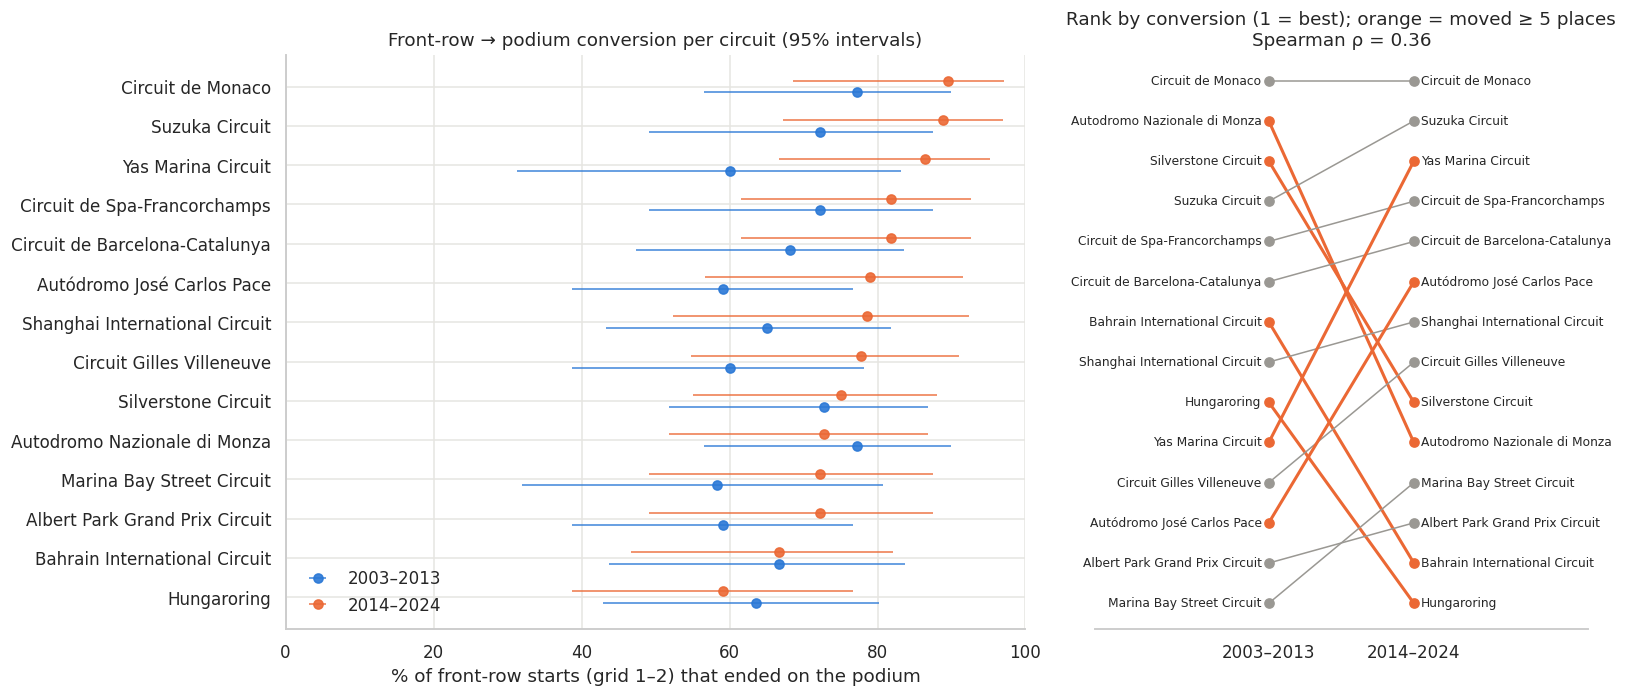

,starts,podiums,podium rate,95% interval
case,,,,
qualified AND started on the front row,815,594,72.9%,70%–76%
"qualified on the front row, started further back (penalty)",37,11,29.7%,17%–46%
started on the front row without qualifying there (promoted),36,23,63.9%,48%–78%


In [39]:
# Left: podium rate of front-row starters per circuit, both periods, with 95% intervals.
# Right: the rank of each circuit in both periods (slope chart): crossing lines = the ranking changed.
g = conv["front_row_grid"][conv["front_row_grid"]["circuit"].isin(eligible)]
order = q1_table.index[::-1]                                   # best 2014–2024 circuit on top
y = {c: i for i, c in enumerate(order)}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [3, 2]})
for p, color, dy in [("2003–2013", BLUE, -0.15), ("2014–2024", ORANGE, 0.15)]:
    t = g[g["period"] == p]
    ys = t["circuit"].map(y) + dy
    ax1.errorbar(t["rate"] * 100, ys, xerr=[(t["rate"] - t["lo"]) * 100, (t["hi"] - t["rate"]) * 100],
                 fmt="o", color=color, ecolor=color, elinewidth=1, capsize=0, label=p, alpha=0.9)
ax1.set_yticks(range(len(order)), order)
ax1.set(xlabel="% of front-row starts (grid 1–2) that ended on the podium", xlim=(0, 100),
        title="Front-row → podium conversion per circuit (95% intervals)")
ax1.legend(frameon=False, loc="lower left")
# slope chart positions: ties broken by name so that no two labels sit on top of each other
pos = {p: q1_table[p].rank(ascending=False, method="first") for p in Q1_PERIODS}
for c in order:
    r1, r2 = pos["2003–2013"][c], pos["2014–2024"][c]
    moved = abs(q1_table.loc[c, "rank change"]) >= 5
    ax2.plot([0, 1], [r1, r2], color=ORANGE if moved else GREY, lw=2 if moved else 1, marker="o")
    ax2.text(-0.05, r1, c, ha="right", va="center", fontsize=8)
    ax2.text(1.05, r2, c, ha="left", va="center", fontsize=8)
ax2.invert_yaxis(); ax2.set_xlim(-1.2, 2.2); ax2.set_xticks([0, 1], list(Q1_PERIODS))
ax2.set_yticks([]); ax2.grid(False); ax2.spines["left"].set_visible(False)
ax2.set_title(f"Rank by conversion (1 = best); orange = moved ≥ 5 places\nSpearman ρ = {rho['by grid']:.2f}")
plt.tight_layout(); plt.show()

# Grid vs qualifying: the two definitions only differ when a penalty moves a car on or off the front row
q1["case"] = np.select(
    [q1["front_row_grid"] & q1["front_row_quali"], q1["front_row_quali"] & ~q1["front_row_grid"],
     q1["front_row_grid"] & ~q1["front_row_quali"]],
    ["qualified AND started on the front row", "qualified on the front row, started further back (penalty)",
     "started on the front row without qualifying there (promoted)"], default="")
cases = q1[q1["case"] != ""].groupby("case")["podium"].agg(starts="size", podiums="sum")
cases["podium rate"] = cases["podiums"] / cases["starts"]
cases["95% interval"] = [f"{lo:.0%}–{hi:.0%}" for lo, hi in zip(*wilson(cases["podiums"], cases["starts"]))]
display(cases.style.format({"podium rate": "{:.1%}"}))


**Answer to Q1** *(numbers from the outputs above)*
- **Front-row starters podium more often after 2014:** 68% → 76% by grid (398 and 453 front-row starts), 68% → 74% by
  qualifying. Conversion went up at 11 of the 14 ranked circuits, consistent with one team often locking out the front
  row (Mercedes, then Red Bull) and cars breaking down less (Q3).
- **Monaco converts best in both periods** (77% → 89%): overtaking there is almost impossible, so the start order
  mostly holds. Suzuka, Yas Marina, Spa and Barcelona complete the 2014–2024 top five.
- **The ranking does change.** The rank correlation between the periods is only 0.36 by grid (0.54 by qualifying).
  Yas Marina rose from 10th to 3rd and Interlagos from 12th to 6th; Monza fell from joint 1st to 10th, Silverstone from
  3rd to 9th, and the Hungaroring is last after 2014 (59%).
- **But most single moves are within noise.** With 10–24 front-row starts per circuit and period, the 95% intervals are
  roughly ±15–25 points and overlap for almost every circuit. Read the ranking as "Monaco on top, the order below it
  reshuffled", not as an exact table.
- **Grid vs qualifying:** the two versions differ for only 73 starts. Drivers who qualified **and** started on the front
  row podiumed 73% of the time; drivers who qualified there but were **penalised** further back only 30%; drivers
  **promoted** onto the front row by someone else's penalty 64%. The grid is the better measure of a real starting chance.

**Grain:** one row per front-row starter per race (2 per race), aggregated to circuit × period. **Missing values:** 21 of
8,910 starters in 2003–2024 have no qualifying position; they cannot be front row by qualifying (left join, no filling).
**Cutoff:** grid and qualifying are both known before the race, so both are legal model inputs.

### 7.2 Q2: Do drivers podium more often at their home race, after controlling for starting position?
**How it is measured.**
- **Home race** = the circuit's country is the driver's country. Nationalities are adjectives ("British") and countries
  are names ("UK"), so a **hand-written map** links them. Every nationality must be in the map, and every country in the
  map must be spelled exactly as in `circuits.country` or be listed as never having hosted a race (both asserted), so
  a typo like "United Kingdom" fails loudly.
- Judgement calls: dual nationalities ("American-Italian") are at home in either country; "East German" drivers count
  Germany as home; "Rhodesian" maps to Zimbabwe (no race). The **circuit's** country is used, not the race name: the San
  Marino GP was in Italy, the 1982 Swiss GP in France.
- **Controlling for starting position:** home drivers might simply start further forward (or back). So home and away
  podium rates are compared **inside grid bins** (1–3, 4–6, 7–10, 11+), and a **logistic regression**
  `podium ~ home + grid bin` estimates the home effect at the same starting position. Its standard errors are clustered
  by race, because drivers in one race compete for the same three places and are not independent rows.
- **Seasons:** all clean seasons (1950–2024), as this is a question about F1 history. Two checks: adding era to the
  model, and repeating it on 2003–2024 only (our model's seasons), once with grid bins and once with the exact grid slot.

In [40]:
import statsmodels.formula.api as smf

# Hand-written map: nationality (an adjective, from drivers.csv) -> country or countries (as written in circuits.csv).
NATIONALITY_TO_COUNTRY = {
    "American": ["USA"], "American-Italian": ["USA", "Italy"], "Argentine": ["Argentina"],
    "Argentine-Italian": ["Argentina", "Italy"], "Australian": ["Australia"], "Austrian": ["Austria"],
    "Belgian": ["Belgium"], "Brazilian": ["Brazil"], "British": ["UK"], "Canadian": ["Canada"],
    "Chilean": ["Chile"], "Chinese": ["China"], "Colombian": ["Colombia"], "Czech": ["Czech Republic"],
    "Danish": ["Denmark"], "Dutch": ["Netherlands"], "East German": ["Germany"], "Finnish": ["Finland"],
    "French": ["France"], "German": ["Germany"], "Hungarian": ["Hungary"], "Indian": ["India"],
    "Indonesian": ["Indonesia"], "Irish": ["Ireland"], "Italian": ["Italy"], "Japanese": ["Japan"],
    "Liechtensteiner": ["Liechtenstein"], "Malaysian": ["Malaysia"], "Mexican": ["Mexico"], "Monegasque": ["Monaco"],
    "New Zealander": ["New Zealand"], "Polish": ["Poland"], "Portuguese": ["Portugal"], "Rhodesian": ["Zimbabwe"],
    "Russian": ["Russia"], "South African": ["South Africa"], "Spanish": ["Spain"], "Swedish": ["Sweden"],
    "Swiss": ["Switzerland"], "Thai": ["Thailand"], "Uruguayan": ["Uruguay"], "Venezuelan": ["Venezuela"],
}
# countries that never hosted a race: listed so that a typo in a country name ("United Kingdom") fails loudly
NO_CIRCUIT = {"Chile", "Colombia", "Czech Republic", "Denmark", "Finland", "Indonesia", "Ireland", "Liechtenstein",
              "New Zealand", "Poland", "Zimbabwe", "Thailand", "Uruguay", "Venezuela"}

unmapped = set(df["drivers"]["nationality"]) - set(NATIONALITY_TO_COUNTRY)
assert not unmapped, f"nationalities without a country: {unmapped}"
circuit_countries = set(df["circuits"]["country"])
mapped_countries = {c for cs in NATIONALITY_TO_COUNTRY.values() for c in cs}
assert mapped_countries - NO_CIRCUIT <= circuit_countries, mapped_countries - NO_CIRCUIT - circuit_countries
assert not NO_CIRCUIT & circuit_countries, NO_CIRCUIT & circuit_countries

GRID_BINS = [0, 3, 6, 10, np.inf]
GRID_LABELS = ["1–3", "4–6", "7–10", "11+"]
q2 = starters.copy()
q2["home"] = [int(c in NATIONALITY_TO_COUNTRY[n]) for n, c in zip(q2["nationality"], q2["country"])]
q2["grid_bin"] = pd.cut(q2["grid_clean"], GRID_BINS, labels=GRID_LABELS)      # pit-lane starters fall in 11+
q2["era"] = pd.cut(q2["year"], [1949, 1979, 2002, 2024], labels=["1950–1979", "1980–2002", "2003–2024"])
assert q2[["grid_bin", "era"]].notna().all().all()
print(f"home starts: {q2['home'].sum():,} of {len(q2):,} starter rows ({q2['home'].mean():.1%})")
print("share starting 11th or further back: home", f"{(q2.loc[q2['home'] == 1, 'grid_bin'] == '11+').mean():.1%},",
      "away", f"{(q2.loc[q2['home'] == 0, 'grid_bin'] == '11+').mean():.1%}")

# 1) raw comparison, and 2) the same comparison inside each grid bin
def by_bin(t):
    g = t.groupby(["grid_bin", "home"], observed=True)["podium"].agg(starts="size", podiums="sum").unstack("home")
    out = pd.DataFrame({"away starts": g[("starts", 0)], "home starts": g[("starts", 1)],
                        "away rate": g[("podiums", 0)] / g[("starts", 0)], "home rate": g[("podiums", 1)] / g[("starts", 1)]})
    out["home − away (pp)"] = (out["home rate"] - out["away rate"]) * 100
    return out

raw_gap = (q2.loc[q2["home"] == 1, "podium"].mean() - q2.loc[q2["home"] == 0, "podium"].mean()) * 100
bins_all = by_bin(q2)
within_gap = np.average(bins_all["home − away (pp)"], weights=bins_all["home starts"])   # weighted by home starts
print(f"raw home − away podium rate: {raw_gap:+.1f} pp | within grid bins (weighted): {within_gap:+.1f} pp")
display(bins_all.style.format({"away rate": "{:.1%}", "home rate": "{:.1%}", "home − away (pp)": "{:+.1f}"}))

# 3) logistic regression podium ~ home + grid bin (+ era), standard errors clustered by race
#    (the drivers of one race share its podium places, so they are not independent rows)
def home_effect(data, formula):
    fit = smf.logit(formula, data=data).fit(disp=0, cov_type="cluster", cov_kwds={"groups": data["raceId"]})
    lo, hi = fit.conf_int().loc["home"]
    return {"home odds ratio": np.exp(fit.params["home"]), "95% CI": f"{np.exp(lo):.2f}–{np.exp(hi):.2f}",
            "p-value": fit.pvalues["home"], "rows": int(fit.nobs), "home rows": int(data["home"].sum())}

models = {
    "all seasons: podium ~ home + grid bin": (q2, "podium ~ home + C(grid_bin)"),
    "all seasons: + era": (q2, "podium ~ home + C(grid_bin) + C(era)"),
    "2003–2024: podium ~ home + grid bin": (q2[q2["year"] >= 2003], "podium ~ home + C(grid_bin)"),
    "2003–2024: podium ~ home + exact grid slot": (q2[(q2["year"] >= 2003)].assign(
        grid_slot=lambda t: t["grid_clean"].clip(upper=20)), "podium ~ home + C(grid_slot)"),
}
q2_models = pd.DataFrame({name: home_effect(data, f) for name, (data, f) in models.items()}).T
display(q2_models.style.format({"home odds ratio": "{:.2f}", "p-value": "{:.3f}"}))


home starts: 1,933 of 24,592 starter rows (7.9%)
share starting 11th or further back: home 59.1%, away 54.5%
raw home − away podium rate: -2.2 pp | within grid bins (weighted): -0.6 pp


,away starts,home starts,away rate,home rate,home − away (pp)
grid_bin,,,,,
1–3,3107,230,55.5%,55.7%,+0.1
4–6,3109,226,26.1%,26.5%,+0.5
7–10,4096,335,9.3%,7.2%,-2.1
11+,12347,1142,1.7%,1.1%,-0.6


,home odds ratio,95% CI,p-value,rows,home rows
all seasons: podium ~ home + grid bin,0.92,0.78–1.08,0.310,24592,1933
all seasons: + era,0.92,0.78–1.09,0.326,24592,1933
2003–2024: podium ~ home + grid bin,0.84,0.57–1.22,0.352,8910,364
2003–2024: podium ~ home + exact grid slot,0.78,0.52–1.16,0.217,8910,364


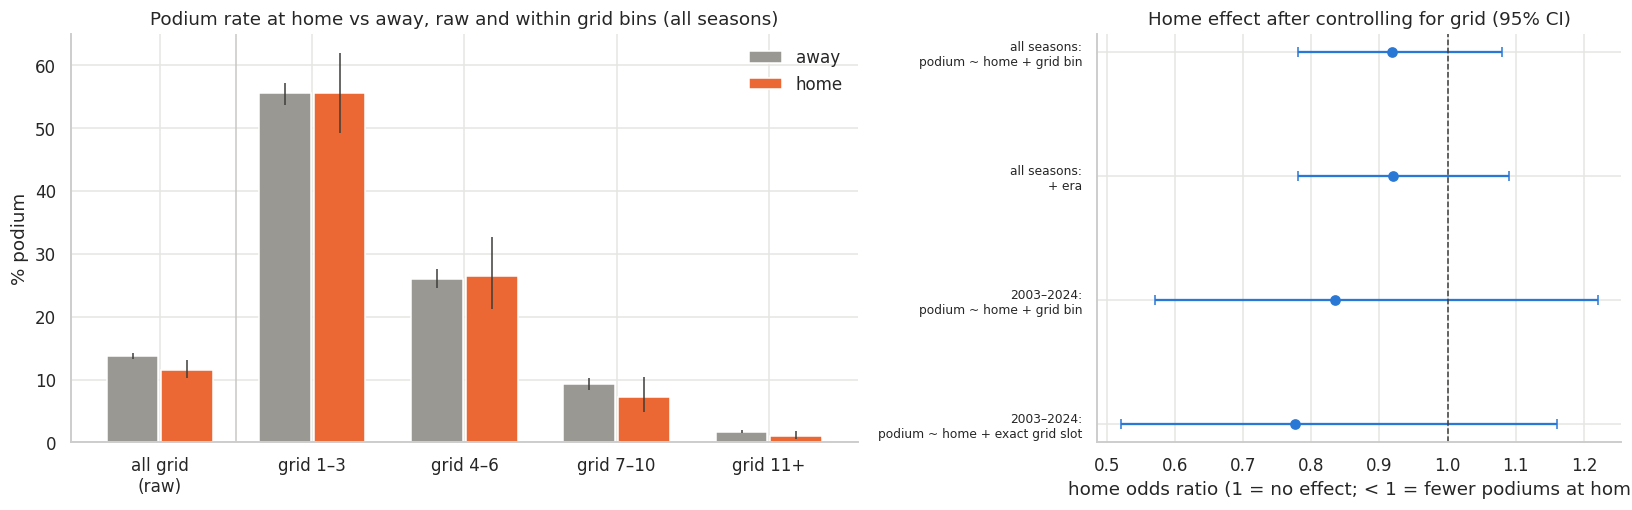

In [41]:
# Left: podium rate at home vs away inside each grid bin (95% intervals), with the raw (unadjusted) rates on the left.
# Right: the home odds ratio from each regression (1 = no home effect).
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [3, 2]})
groups = ["all grid\n(raw)"] + [f"grid {b}" for b in GRID_LABELS]
x = np.arange(len(groups))
for home, color, dx, label in [(0, GREY, -0.18, "away"), (1, ORANGE, 0.18, "home")]:
    t = q2[q2["home"] == home]
    k = [t["podium"].sum()] + [t.loc[t["grid_bin"] == b, "podium"].sum() for b in GRID_LABELS]
    n = [len(t)] + [int((t["grid_bin"] == b).sum()) for b in GRID_LABELS]
    rate = np.array(k) / np.array(n)
    lo, hi = wilson(k, n)
    ax1.bar(x + dx, rate * 100, width=0.34, color=color, label=label)
    ax1.errorbar(x + dx, rate * 100, yerr=[(rate - lo) * 100, (hi - rate) * 100], fmt="none", ecolor="#3d3d3a", lw=1)
ax1.axvline(0.5, color="#c9c8c3", lw=1)
ax1.set_xticks(x, groups)
ax1.set(ylabel="% podium", title="Podium rate at home vs away, raw and within grid bins (all seasons)")
ax1.legend(frameon=False)

orr = q2_models["home odds ratio"].astype(float)
ci = q2_models["95% CI"].str.split("–", expand=True).astype(float)
yy = np.arange(len(orr))[::-1]
ax2.errorbar(orr, yy, xerr=[orr - ci[0], ci[1] - orr], fmt="o", color=BLUE, ecolor=BLUE, capsize=3)
ax2.axvline(1, color="#3d3d3a", lw=1, ls="--")
ax2.set_yticks(yy, [m.replace(": ", ":\n") for m in q2_models.index], fontsize=8)
ax2.set(xlabel="home odds ratio (1 = no effect; < 1 = fewer podiums at home)",
        title="Home effect after controlling for grid (95% CI)")
plt.tight_layout(); plt.show()


**Answer to Q2** *(numbers from the outputs above)*
- **Raw, home drivers podium *less*:** 11.6% vs 13.8% (−2.2 points). That gap is about **where they start**: 59% of home
  starts were from 11th or further back, against 55% of away starts (many one-off local entries in small teams).
- **Within the same grid bin, the gap almost disappears:** +0.1 points (grid 1–3), +0.5 (4–6), −2.1 (7–10), −0.6 (11+);
  −0.6 points on average.
- **Regression:** home odds ratio **0.92 (95% CI 0.78–1.08, p = 0.31)** with grid bins; 0.92 with era added. On 2003–2024
  alone: 0.84 (0.57–1.22) with grid bins, 0.78 (0.52–1.16) with the exact grid slot. Every interval contains 1.
- **Conclusion: no evidence of a home advantage once starting position is accounted for.** If anything the estimates lean
  slightly below 1, but none is distinguishable from zero. Caveat: 2003–2024 has only 364 home starts, so a modest effect
  (± 20–40% in odds) cannot be ruled out there, and this is an association, not a causal effect.

**Grain:** one row per starter per race. **Missing values:** none: every starter has a nationality and every circuit a
country (asserted); nationalities without a circuit are "away" by construction. **Cutoff:** nationality, circuit and grid
are known before the race, so a `home_race` flag is a legal feature (stage C), though this answer suggests it will add little.

### 7.3 Q3: Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?
**How it is measured.**
- **Rate = mechanical retirements ÷ race starts** of the team in the period. Starts only: a car that never started cannot
  retire (those rows were removed in §3.2; asserted).
- **Mechanical** = status category `mechanical` (§6.1): a part of the car failed. Crashes, driver causes and
  disqualifications are not mechanical. **Strict rate** = mechanical only; **broad rate** adds the `ambiguous` labels
  ("Retired", "Wheel", "Puncture", ...). If the answer only holds under one of them, it is not a robust answer.
- **Teams are compared by lineage** (§6.2): five teams raced under two or more names in 2014–2024 (e.g. Lotus F1 →
  Renault → Alpine), so counting by `constructorId` would split one team's starts over several ids. A table by
  `constructorId` is shown for reference.
- **Minimum 40 starts per period** (about one season with two cars). This removes Caterham (33 starts, 2014 only).
- **Periods:** 2014–2021 (turbo-hybrid, 8 seasons) vs 2022–2024 (ground-effect rules, 3 seasons): the second period has
  far fewer starts per team, so its rates are less certain.

In [42]:
MIN_STARTS = 40          # per lineage and period, about one season of two cars

q3 = add_lineage(starters[starters["year"].between(2014, 2024)].drop(columns=["circuit"]))
q3["period"] = np.where(q3["year"] <= 2021, "2014–2021", "2022–2024")
q3["mech"] = (q3["category"] == "mechanical").astype(int)                       # strict
q3["mech_broad"] = q3["category"].isin(["mechanical", "ambiguous"]).astype(int)  # strict + ambiguous labels
assert not (q3["category"] == "never_started").any()     # the denominator is race starts only (§3.2)

def rates(t, by):
    g = t.groupby(by + ["period"]).agg(starts=("mech", "size"), mechanical=("mech", "sum"),
                                       broad=("mech_broad", "sum")).reset_index()
    g["rate"] = g["mechanical"] / g["starts"]
    g["lo"], g["hi"] = wilson(g["mechanical"], g["starts"])
    g["broad rate"] = g["broad"] / g["starts"]
    return g

q3_lin = rates(q3, ["lineage"])
q3_lin = q3_lin[q3_lin["starts"] >= MIN_STARTS]
# names each lineage raced under in each period, for the labels (e.g. RB = Toro Rosso / AlphaTauri / RB F1 Team)
raced_as = q3.groupby(["lineage", "period"])["name"].apply(lambda s: " / ".join(dict.fromkeys(s)))
q3_lin["raced as"] = [raced_as[(l, p)] for l, p in zip(q3_lin["lineage"], q3_lin["period"])]

for p in ["2014–2021", "2022–2024"]:
    t = q3_lin[q3_lin["period"] == p].sort_values("rate", ascending=False).set_index("lineage")
    t["rank"] = t["rate"].rank(ascending=False, method="min").astype(int)
    t["rank (broad)"] = t["broad rate"].rank(ascending=False, method="min").astype(int)
    overall = q3.loc[q3["period"] == p, "mech"].mean()
    print(f"\n{p}: {int(t['starts'].sum()):,} starts, overall mechanical-retirement rate {overall:.1%}")
    display(t[["raced as", "starts", "mechanical", "rate", "lo", "hi", "rank", "broad rate", "rank (broad)"]]
            .style.format({"rate": "{:.1%}", "lo": "{:.1%}", "hi": "{:.1%}", "broad rate": "{:.1%}"}))

wide = q3_lin.pivot(index="lineage", columns="period", values="rate").dropna()
print("Spearman rank correlation of the two periods (lineages in both):",
      round(wide["2014–2021"].corr(wide["2022–2024"], method="spearman"), 2))
# the same rate by constructorId (the dataset's own team ids), for reference
by_id = rates(q3, ["name"]).query("starts >= @MIN_STARTS").pivot(index="name", columns="period", values="rate")
display(by_id.sort_values("2014–2021", ascending=False).style.format("{:.1%}", na_rep="–"))



2014–2021: 3,213 starts, overall mechanical-retirement rate 8.9%


,raced as,starts,mechanical,rate,lo,hi,rank,broad rate,rank (broad)
lineage,,,,,,,,,
RB,Toro Rosso / AlphaTauri,319,46,14.4%,11.0%,18.7%,1,16.3%,2
Alpine,Lotus F1 / Renault / Alpine F1 Team,318,42,13.2%,9.9%,17.4%,2,17.0%,1
McLaren,McLaren,316,40,12.7%,9.4%,16.8%,3,15.5%,3
Red Bull,Red Bull,318,34,10.7%,7.8%,14.6%,4,11.6%,5
Sauber,Sauber / Alfa Romeo,319,25,7.8%,5.4%,11.3%,5,9.7%,6
Haas,Haas F1 Team,241,18,7.5%,4.8%,11.5%,6,12.4%,4
Williams,Williams,319,23,7.2%,4.9%,10.6%,7,9.7%,6
Manor,Marussia / Manor Marussia,108,7,6.5%,3.2%,12.8%,8,8.3%,8
Aston Martin,Force India / Racing Point / Aston Martin,317,19,6.0%,3.9%,9.2%,9,6.9%,9



2022–2024: 1,352 starts, overall mechanical-retirement rate 5.4%


,raced as,starts,mechanical,rate,lo,hi,rank,broad rate,rank (broad)
lineage,,,,,,,,,
Alpine,Alpine F1 Team,135,14,10.4%,6.3%,16.7%,1,10.4%,1
Sauber,Alfa Romeo / Sauber,136,12,8.8%,5.1%,14.8%,2,10.3%,2
RB,AlphaTauri / RB F1 Team,136,8,5.9%,3.0%,11.2%,3,8.8%,3
Williams,Williams,134,7,5.2%,2.6%,10.4%,4,8.2%,4
Ferrari,Ferrari,134,6,4.5%,2.1%,9.4%,5,6.7%,5
Haas,Haas F1 Team,135,6,4.4%,2.1%,9.4%,6,5.2%,7
Mercedes,Mercedes,136,6,4.4%,2.0%,9.3%,7,4.4%,8
McLaren,McLaren,136,5,3.7%,1.6%,8.3%,8,3.7%,10
Red Bull,Red Bull,136,5,3.7%,1.6%,8.3%,8,4.4%,8


Spearman rank correlation of the two periods (lineages in both): 0.38


period,2014–2021,2022–2024
name,,
Lotus F1,17.3%,–
Toro Rosso,16.1%,–
Renault,13.1%,–
McLaren,12.7%,3.7%
Red Bull,10.7%,3.7%
Sauber,10.6%,2.1%
AlphaTauri,9.1%,6.8%
Racing Point,8.0%,–
Haas F1 Team,7.5%,4.4%


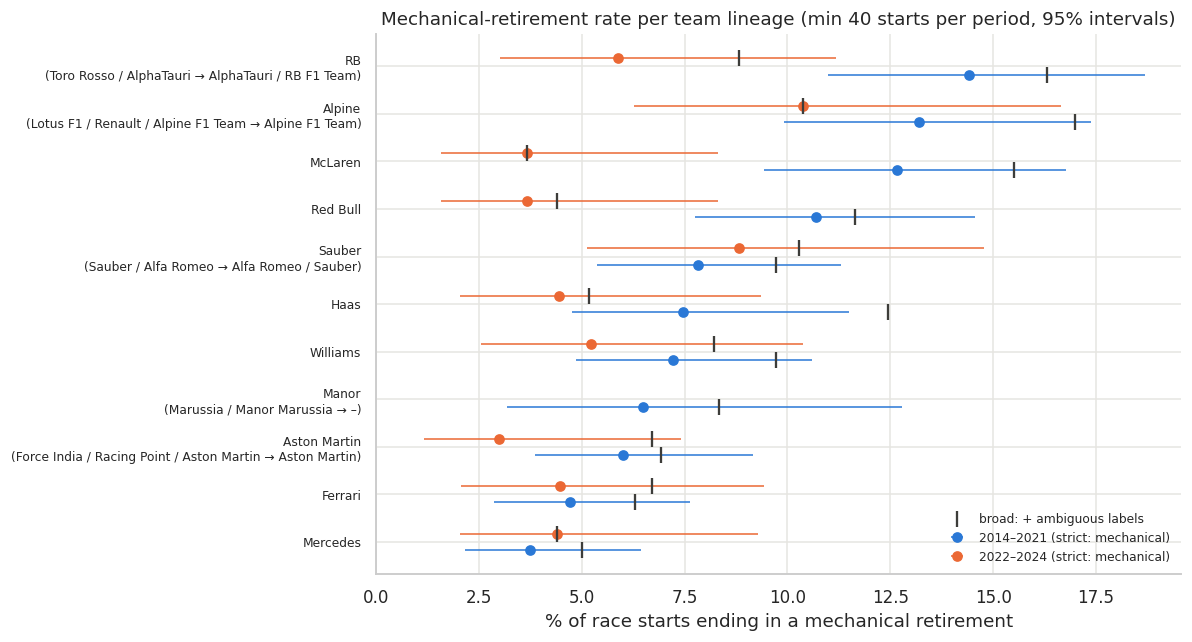

In [43]:
# One row per lineage: mechanical-retirement rate in 2014–2021 (blue) and 2022–2024 (orange) with 95% intervals;
# the small black tick is the broad rate (mechanical + ambiguous labels).
order = (q3_lin[q3_lin["period"] == "2014–2021"].sort_values("rate")["lineage"].tolist())
order = [l for l in q3_lin["lineage"].unique() if l not in order] + order
y = {l: i for i, l in enumerate(order)}
fig, ax = plt.subplots(figsize=(11, 6))
for p, color, dy in [("2014–2021", BLUE, -0.17), ("2022–2024", ORANGE, 0.17)]:
    t = q3_lin[q3_lin["period"] == p]
    ys = t["lineage"].map(y) + dy
    ax.errorbar(t["rate"] * 100, ys, xerr=[(t["rate"] - t["lo"]) * 100, (t["hi"] - t["rate"]) * 100],
                fmt="o", color=color, ecolor=color, elinewidth=1, label=f"{p} (strict: mechanical)")
    ax.scatter(t["broad rate"] * 100, ys, marker="|", s=120, color="#3d3d3a", zorder=3,
               label="broad: + ambiguous labels" if p == "2022–2024" else None)
def label(l):
    a, b = raced_as.get((l, "2014–2021"), "–"), raced_as.get((l, "2022–2024"), "–")
    same_name = all(x == "–" or x.startswith(l) for x in (a, b))     # e.g. Ferrari, or Haas = "Haas F1 Team"
    return l if same_name else f"{l}\n({a} → {b})"
labels = [label(l) for l in order]
ax.set_yticks(range(len(order)), labels, fontsize=8)
ax.set_xlim(left=0)
ax.set(xlabel="% of race starts ending in a mechanical retirement",
       title=f"Mechanical-retirement rate per team lineage (min {MIN_STARTS} starts per period, 95% intervals)")
ax.legend(frameon=False, loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()


**Answer to Q3** *(numbers from the outputs above)*
- **Cars broke down less in 2022–2024:** 8.9% of starts ended in a mechanical retirement in 2014–2021, 5.4% in 2022–2024.
- **2014–2021, highest:** RB lineage (Toro Rosso / AlphaTauri) **14.4%**, Alpine lineage (Lotus F1 / Renault) **13.2%**,
  McLaren **12.7%** (25 of its 40 failures came in 2015–2017, its seasons with Honda engines), Red Bull 10.7%.
  **Lowest:** Mercedes 3.8%, Ferrari 4.7%: the two teams that won most in that period.
- **2022–2024, highest:** Alpine **10.4%**, Sauber lineage (Alfa Romeo / Sauber) **8.8%**, RB lineage 5.9%.
  **Lowest:** Aston Martin 3.0%, McLaren and Red Bull 3.7%.
- **The ranking reshuffled** (rank correlation 0.38). McLaren went from 3rd to joint 8th and Red Bull from 4th to joint
  8th; Sauber moved up from 5th to 2nd. **Alpine and the RB lineage are in the top three in both periods.**
- **Robustness:** with the ambiguous labels added, the top three are the same teams in both periods (2014–2021 with
  Alpine and RB swapping places). The answer does not depend on how ambiguous labels are counted.
- **Caveat:** in 2022–2024 each team has about 135 starts and 4–14 failures, so intervals are wide (Alpine 6–17%) and
  most teams overlap. Only the big moves (McLaren and Red Bull dropping from the top four to the bottom, Alpine
  staying high) are clearly more than noise.
- **Why lineage matters:** counted by `constructorId`, Alfa Romeo (12.5% in 2022–23) and Sauber (2.1% in 2024, 48 starts)
  would appear as two teams with very different records, although they are one team in one factory.

**Grain:** one row per car start, aggregated to lineage × period. **Missing values:** none: every result has a status
and every status a category (asserted in §6.1). **Cutoff:** a race's status is **post-race** information. It is used here
only to describe history; as a model feature only a team's *past* reliability (earlier races) is allowed (stage C).

### 7.4 Hand-off to stage C
- Maps ready to reuse: `df["status"]["category"]` (§6.1), `add_lineage()` (§6.2), `NATIONALITY_TO_COUNTRY` (§7.2) for a
  `home_race` feature.
- `starters` (§7.0): every clean starter with season, circuit, country, nationality, qualifying position and status category.
- **Constructor form windows must restart after a gap** (or follow the lineage): five `constructorId`s were reused for
  unrelated teams decades apart (§6.2).
- Expect little from `home_race` (Q2) and a lot from starting position (Q1); team reliability changes between eras (Q3),
  so reliability features should look only at recent races.